**Dataset:** Online Shoppers Purchasing Intention Dataset (UCI Machine Learning Repository)  
**Quy mô:** 12,330 phiên truy cập (sessions), 17 đặc trưng và 1 biến mục tiêu `Revenue`.

---
## Lộ trình phân tích (EDA Roadmap)
- **Giai đoạn 1: Data Audit & Kiểm định chất lượng dữ liệu** (Cấu trúc, kiểu dữ liệu, khuyết thiếu, trùng lặp, tính nhất quán logic).
- **Giai đoạn 2: Phân tích đơn biến (Univariate Analysis)** (Biến mục tiêu `Revenue`, nhóm biến phân loại và nhóm biến số lượng).
- **Giai đoạn 3: Phân tích hai biến & đa biến (Bivariate & Multivariate Analysis)** (Quan hệ với `Revenue`, ma trận tương quan)

---
## Giai đoạn 1: Data Audit & Kiểm định chất lượng dữ liệu
1. Khám phá kích thước, cấu trúc và kiểm tra kiểu dữ liệu thực tế so với tài liệu mô tả.
2. Kiểm tra dữ liệu khuyết thiếu (Missing values) và dòng trùng lặp (Duplicates).
3. Thực hiện các kiểm tra tính nhất quán logic (Sanity & Consistency checks).
4. Đóng gói báo cáo kiểm toán chất lượng dữ liệu (Data Quality Report) làm tiền đề cho phân tích sâu.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

### 1.1. Đọc dữ liệu và xem các dòng đầu tiên (Data Loading & Preview)


In [2]:
df = pd.read_csv('online_shoppers_intention.csv')
print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng (sessions), {df.shape[1]} cột")
df.head()

Kích thước dữ liệu: 12,330 dòng (sessions), 18 cột


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 1.2. Kiểm tra thông tin cấu trúc & kiểu dữ liệu

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

### 1.3. Kiểm tra giá trị khuyết thiếu (Missing values) & Dòng trùng lặp (Duplicates)


In [4]:
missing = df.isna().sum()
print("=== KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU ===")
if missing.sum() == 0:
    print("Tập dữ liệu KHÔNG có giá trị khuyết thiếu (0 missing values)")
else:
    print(missing[missing > 0])

n_dups = df.duplicated().sum()
print(f"\n=== KIỂM TRA DÒNG TRÙNG LẶP (DUPLICATES) ===")
print(f"Số dòng trùng lặp hoàn toàn: {n_dups} ({n_dups / len(df):.2%})")

if n_dups > 0:
    print(f"\nVí dụ {n_dups} dòng trùng lặp:")
    dup_samples = df[df.duplicated(keep=False)].sort_values(by=list(df.columns[:5])).head(6)
    display(dup_samples)


=== KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU ===
Tập dữ liệu KHÔNG có giá trị khuyết thiếu (0 missing values)

=== KIỂM TRA DÒNG TRÙNG LẶP (DUPLICATES) ===
Số dòng trùng lặp hoàn toàn: 125 (1.01%)

Ví dụ 125 dòng trùng lặp:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False


### 1.4. Tổng kết

| Tiêu chí kiểm toán | Kết quả phát hiện | Đánh giá & Hướng xử lý |
|---|---|---|
| **Kích thước & Độ đầy đủ** | 12,330 phiên, 0 missing value | Dữ liệu đầy đủ 100%, không cần áp dụng thuật toán điền khuyết (imputer). |
| **Kiểu dữ liệu thực tế** | `PageValues`, `SpecialDay`, các `Duration` là float | Dùng kiểu dữ liệu thực tế từ `df.dtypes`, không lấy theo bảng mô tả UCI (ghi nhầm Integer). |


---
## Giai đoạn 2: Phân tích đơn biến (Univariate Analysis)

1. **Biến mục tiêu (Target)**: 
   - `Revenue` - Đánh giá phân phối nhãn & mức độ mất cân bằng lớp
2. **Nhóm biến phân loại & định danh (8 biến - Categorical)** $\rightarrow$ Khảo sát tần suất xuất hiện
   - *Ngữ cảnh & Mùa vụ:* `Month`, `VisitorType`, `Weekend`, `SpecialDay`
   - *Kỹ thuật & Nguồn lưu lượng:* `OperatingSystems` , `Browser`, `Region`, `TrafficType`
3. **Nhóm biến số lượng & liên tục (9 biến - Numerical)** $\rightarrow$ Đo lường độ lệch, tỷ lệ số 0 và Outliers
   - *Số lượt xem trang:* `Administrative`, `Informational`, `ProductRelated` 
   - *Thời lượng xem trang:* `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` 
   - *Chỉ số Web Analytics:* `BounceRates`, `ExitRates`, `PageValues`
   


### 2.1. Biến mục tiêu `Revenue` & Mất cân bằng dữ liệu


,Số phiên (Sessions),Tỷ lệ (%)
Revenue,,
False,10422,84.53
True,1908,15.47


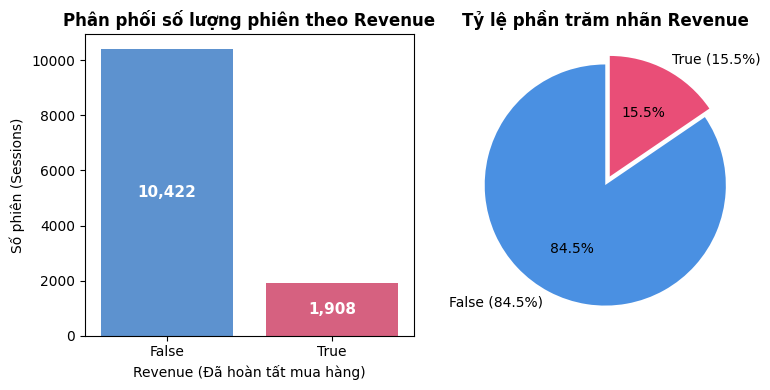

In [5]:
revenue_counts = df['Revenue'].value_counts()
revenue_pct = df['Revenue'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Số phiên (Sessions)': revenue_counts,
    'Tỷ lệ (%)': revenue_pct.round(2)
})
display(summary_target)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Barplot
sns.barplot(
    x=revenue_counts.index.astype(str),
    y=revenue_counts.values,
    hue=revenue_counts.index.astype(str),
    legend=False,
    ax=axes[0],
    palette=['#4A90E2', '#E94E77']
)
axes[0].set_title('Phân phối số lượng phiên theo Revenue', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue (Đã hoàn tất mua hàng)')
axes[0].set_ylabel('Số phiên (Sessions)')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}",
                    (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Pie chart
axes[1].pie(
    revenue_pct,
    labels=[f"False ({revenue_pct[False]:.1f}%)", f"True ({revenue_pct[True]:.1f}%)"],
    autopct='%1.1f%%',
    colors=['#4A90E2', '#E94E77'],
    startangle=90,
    explode=[0, 0.08]
)
axes[1].set_title('Tỷ lệ phần trăm nhãn Revenue', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 2.2. Phân tích đơn biến: Tần suất xuất hiện & Tỷ trọng của 8 biến phân loại
Khảo sát toàn bộ phân bố của 8 biến ngữ cảnh: `Month`, `VisitorType`, `Weekend`, `SpecialDay`, `OperatingSystems`, `Region`, `Browser`, `TrafficType`. Trên mỗi cột hiển thị đồng thời **Số lượng phiên (hàng trên)** và **Tỷ lệ % (hàng dưới)** để đánh giá cả quy mô tuyệt đối lẫn tỷ trọng tương đối.

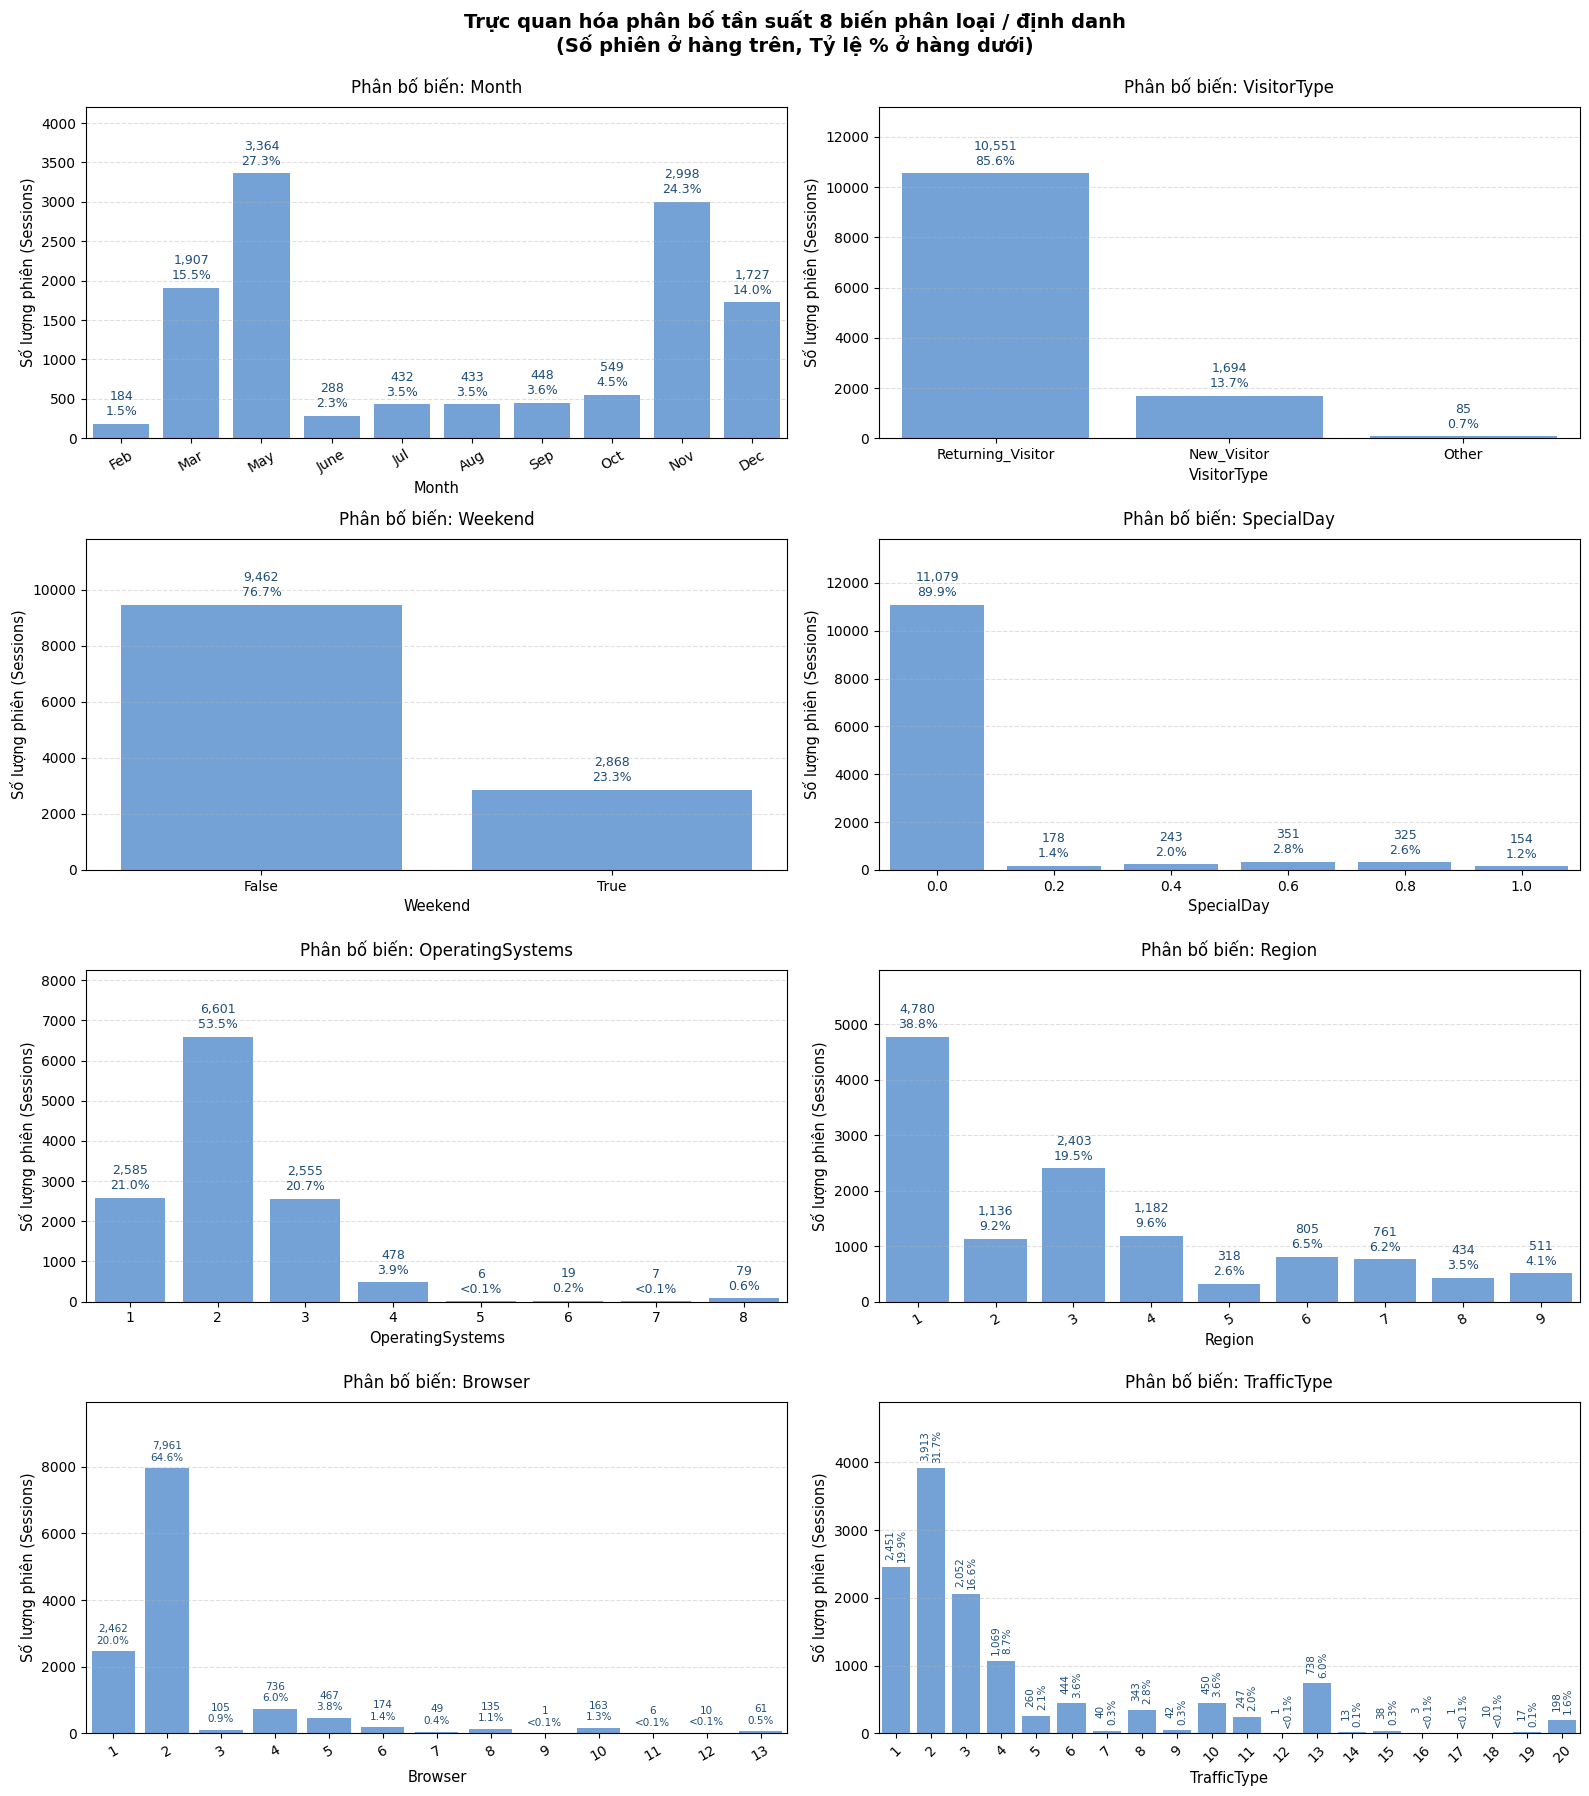

In [6]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plot_cols = ['Month', 'VisitorType', 'Weekend', 'SpecialDay', 'OperatingSystems', 'Region', 'Browser', 'TrafficType']

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
n_total = len(df)

for i, col in enumerate(plot_cols):
    ax = axes[i]
    vc = df[col].value_counts()
    if col == 'Month':
        order = [m for m in month_order if m in vc.index]
    elif col in ['SpecialDay', 'OperatingSystems', 'Region', 'Browser', 'TrafficType']:
        order = sorted(vc.index)
    else:
        order = vc.index.tolist()
    
    counts = [vc.get(val, 0) for val in order]
    
    sns.barplot(
        x=[str(x) for x in order], 
        y=counts, 
        color='#4A90E2',
        alpha=0.85,
        ax=ax
    )
    ax.set_title(f'Phân bố biến: {col}', fontsize=12, pad=10)
    ax.set_xlabel(col, fontsize=10.5)
    ax.set_ylabel('Số lượng phiên (Sessions)', fontsize=10.5)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    # Hiển thị số lượng (hàng trên) và % (hàng dưới) trên đầu mỗi cột
    is_dense = len(order) > 13
    for p, c in zip(ax.patches, counts):
        h = p.get_height()
        pct = (c / n_total) * 100
        if c > 0:
            pct_str = f"{pct:.1f}%" if pct >= 0.1 else "<0.1%"
            label = f"{c:,}\n{pct_str}"
            ax.annotate(
                label, 
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', 
                fontsize=7.5 if len(order) > 10 else 9,
                color='#1F4E79',
                rotation=90 if is_dense else 0,
                xytext=(0, 4), textcoords='offset points'
            )
            
    # Tăng giới hạn trục Y để nhãn không bị tràn khung
    ax.set_ylim(0, max(counts) * 1.25)
    if len(order) > 8:
        ax.tick_params(axis='x', rotation=30 if len(order) <= 13 else 45)

plt.suptitle('Trực quan hóa phân bố tần suất 8 biến phân loại / định danh\n(Số phiên ở hàng trên, Tỷ lệ % ở hàng dưới)', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### 2.3. Phân tích đơn biến: Nhóm 9 biến số lượng / liên tục (Numerical Features)
Khảo sát 9 biến đo lường hành vi người dùng: `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`

#### 2.3.1. Thống kê, Độ lệch (Skewness) & Tỷ lệ giá trị bằng 0
Tính Mean, Median, Độ lệch chuẩn, Độ lệch, Tỷ lệ giá trị bằng 0 và số lượng outliers theo quy tắc $1.5 \times IQR$.


=== BẢNG THỐNG KÊ MÔ TẢ 9 BIẾN SỐ LƯỢNG / LIÊN TỤC ===


,count,mean,std,min,25%,median,75%,max,skew,zero_pct,outliers_count,outliers_pct
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00,1.96,46.78,404,3.28
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75,5.62,47.88,1172,9.51
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00,4.04,78.66,2631,21.34
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38,7.58,80.49,2405,19.51
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00,4.34,0.31,987,8.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52,7.26,6.12,961,7.79
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20,2.95,44.75,1551,12.58
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20,2.15,0.62,1099,8.91
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76,6.38,77.86,2730,22.14


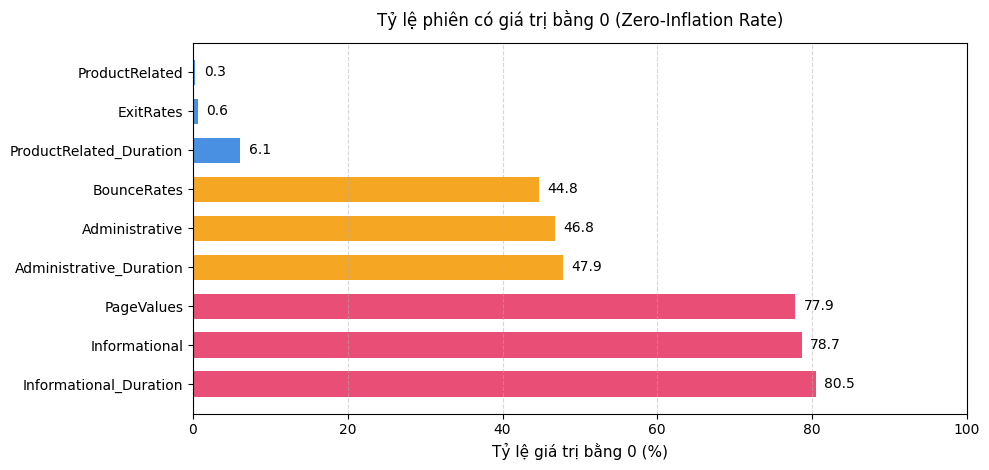

In [7]:
num_cols = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues'
]

# 1. Lập bảng thống kê mô tả mở rộng
num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary.rename(columns={'50%': 'median'}, inplace=True)
num_summary['skew'] = df[num_cols].skew()
num_summary['zero_pct'] = (df[num_cols] == 0).mean() * 100

# Tính số lượng Outliers theo quy tắc 1.5 * IQR
outlier_counts = []
for c in num_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    outlier_counts.append(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())

num_summary['outliers_count'] = outlier_counts
num_summary['outliers_pct'] = (num_summary['outliers_count'] / len(df)) * 100

print("=== BẢNG THỐNG KÊ MÔ TẢ 9 BIẾN SỐ LƯỢNG / LIÊN TỤC ===")
display(num_summary.round(2))

# 2. Trực quan hóa tỷ lệ giá trị bằng 0 (Zero-Inflation Rate)
zero_pct = (df[num_cols] == 0).mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
colors = ['#E94E77' if val > 70 else ('#F5A623' if val > 40 else '#4A90E2') for val in zero_pct.values]
bars = ax.barh(zero_pct.index, zero_pct.values, color=colors, edgecolor='none', height=0.65)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.1f}', 
                (w, bar.get_y() + bar.get_height() / 2.),
                xytext=(6, 0), textcoords='offset points',
                ha='left', va='center', fontsize=10)

ax.set_xlim(0, 100)
ax.set_title('Tỷ lệ phiên có giá trị bằng 0 (Zero-Inflation Rate)', fontsize=12, pad=12)
ax.set_xlabel('Tỷ lệ giá trị bằng 0 (%)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 2.3.2. So sánh toàn diện 9 biến số lượng: Phân phối gốc, Biến đổi Log (`log1p`) & Boxplot Outliers

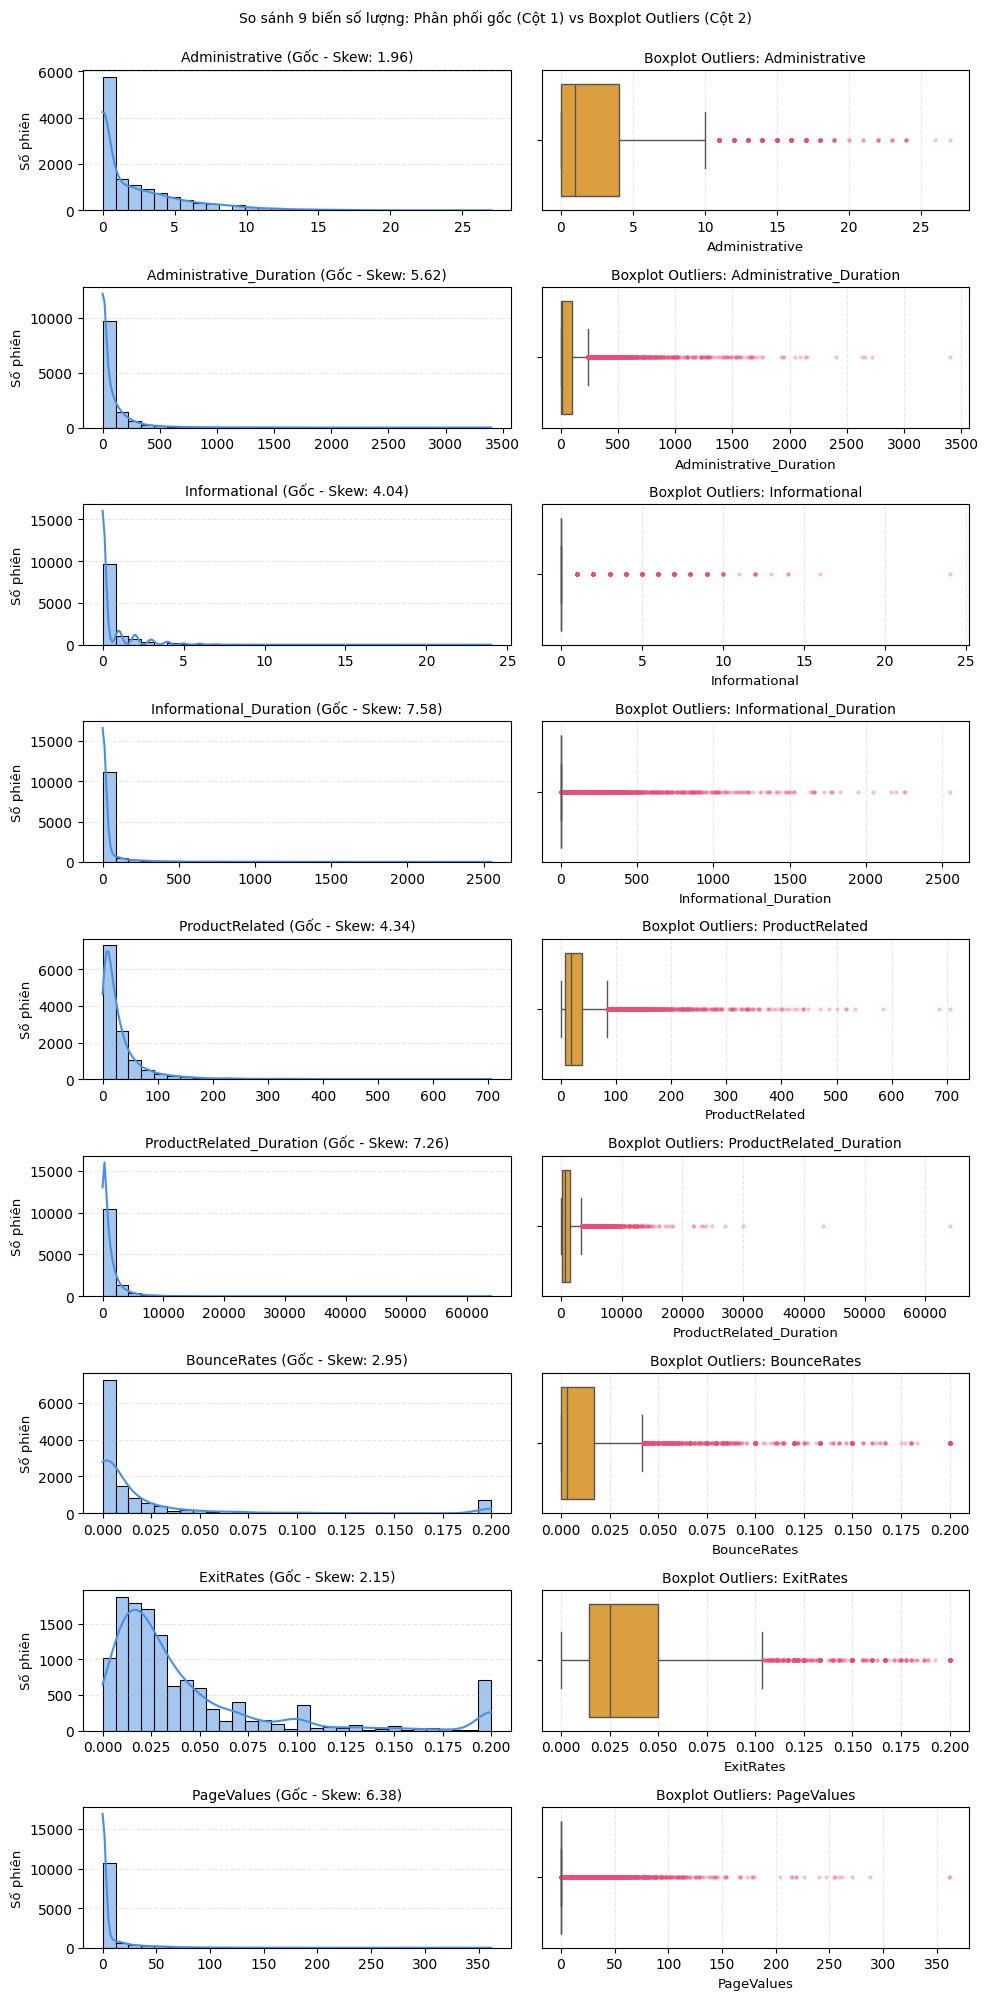

In [13]:
fig, axes = plt.subplots(9, 2, figsize=(10, 20))

for i, col in enumerate(num_cols):
    # 1. Cột 1: Phân phối gốc
    ax_orig = axes[i, 0]
    sns.histplot(df[col], kde=True, bins=30, ax=ax_orig, color='#4A90E2')
    ax_orig.set_title(f'{col} (Gốc - Skew: {df[col].skew():.2f})', fontsize=10)
    ax_orig.set_ylabel('Số phiên', fontsize=9.5)
    ax_orig.set_xlabel('')
    ax_orig.grid(axis='y', linestyle='--', alpha=0.3)
    
    # 3. Cột 3: Boxplot nhận diện Outliers trên miền giá trị gốc
    ax_box = axes[i, 1]
    sns.boxplot(
        x=df[col], 
        ax=ax_box, 
        color='#F5A623',
        flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.35, 'markerfacecolor': '#E94E77', 'markeredgecolor': 'none'}
    )
    ax_box.set_title(f'Boxplot Outliers: {col}', fontsize=10)
    ax_box.set_xlabel(col, fontsize=9.5)
    ax_box.grid(axis='x', linestyle='--', alpha=0.3)

plt.suptitle('So sánh 9 biến số lượng: Phân phối gốc (Cột 1) vs Boxplot Outliers (Cột 2)', fontsize=10, y=0.998)
plt.tight_layout()
plt.show()


### 2.4. Tổng kết Giai đoạn 2 & Định hướng kỹ thuật

| Nhóm biến | Đặc tính cốt lõi | Định hướng xử lý (Modeling) |
|---|---|---|
| **Biến mục tiêu `Revenue`** | Mất cân bằng: **84.5% False vs 15.5% True** | Dùng `StratifiedKFold`; đánh giá bằng **PR-AUC / F1-score** (không dùng Accuracy). |
| **Biến phân loại (Categorical)** | Thiếu tháng 1, 4; nhiều mã có tỷ trọng siêu nhỏ (< 0.5%) | Gom các mã nhỏ lẻ thành `'Other'` trước khi One-Hot Encoding để tránh overfit. |
| **Zero-Inflation (Nhiều số 0)** | `Informational` (~80%), `PageValues` (77.9%) hầu hết = 0 | Tạo đặc trưng cờ nhị phân (e.g. `has_page_values = PV > 0`), dùng Tree/Hurdle models. |
| **Độ lệch (Skewness)** | Cả 9 biến đều lệch phải nặng (Skewness 1.96 $\to$ 7.58) | Áp dụng `log1p(x)` cho các biến ít số 0 (`ProductRelated`, `ProductRelated_Duration`). |
| **Ngoại lai (Outliers)** | Nhiều phiên cực dài (xem > 400 trang) | **Giữ nguyên Outliers**; ưu tiên dùng Tree-based models (XGBoost, LightGBM) vì kháng ngoại lai tốt. |

---
## Giai đoạn 3: Phân tích hai biến & đa biến
Đối chiếu các đặc trưng với biến mục tiêu `Revenue` qua 3 nội dung trọng tâm:
- **3.1. Hành vi trên trang**: So sánh số trang xem, thời lượng duyệt, tỷ lệ thoát (`Bounce/Exit`) và giá trị trang (`PageValues`).
- **3.2. Nhóm khách hàng & Bối cảnh**: Đo lường tỷ lệ chuyển đổi theo loại khách, mùa vụ, cuối tuần và ngày lễ.
- **3.3. Tương quan đa biến**: Đo lường đa cộng tuyến (Spearman)

---
### 3.1. Hành vi trên trang của nhóm mua hàng (`Revenue = True`) vs Không mua (`False`)
#### 3.1.1. So sánh Số trang xem & Thời lượng duyệt web
Kiểm chứng: *Khách chốt đơn có xem nhiều trang và ở lại website lâu hơn so với khách không mua?*

=== SO SÁNH GIÁ TRỊ TRUNG VỊ VÀ TRUNG BÌNH THEO REVENUE ===


,Median (False),Median (True),Tỷ lệ tăng Median,Mean (False),Mean (True)
ProductRelated,16.00,29.000000,1.81,28.71,48.21
ProductRelated_Duration,510.19,1109.906250,2.18,1069.99,1876.21
Administrative,0.00,2.000000,NaN,2.12,3.39
Administrative_Duration,0.00,52.366667,NaN,73.74,119.48
Informational,0.00,0.000000,NaN,0.45,0.79
Informational_Duration,0.00,0.000000,NaN,30.24,57.61


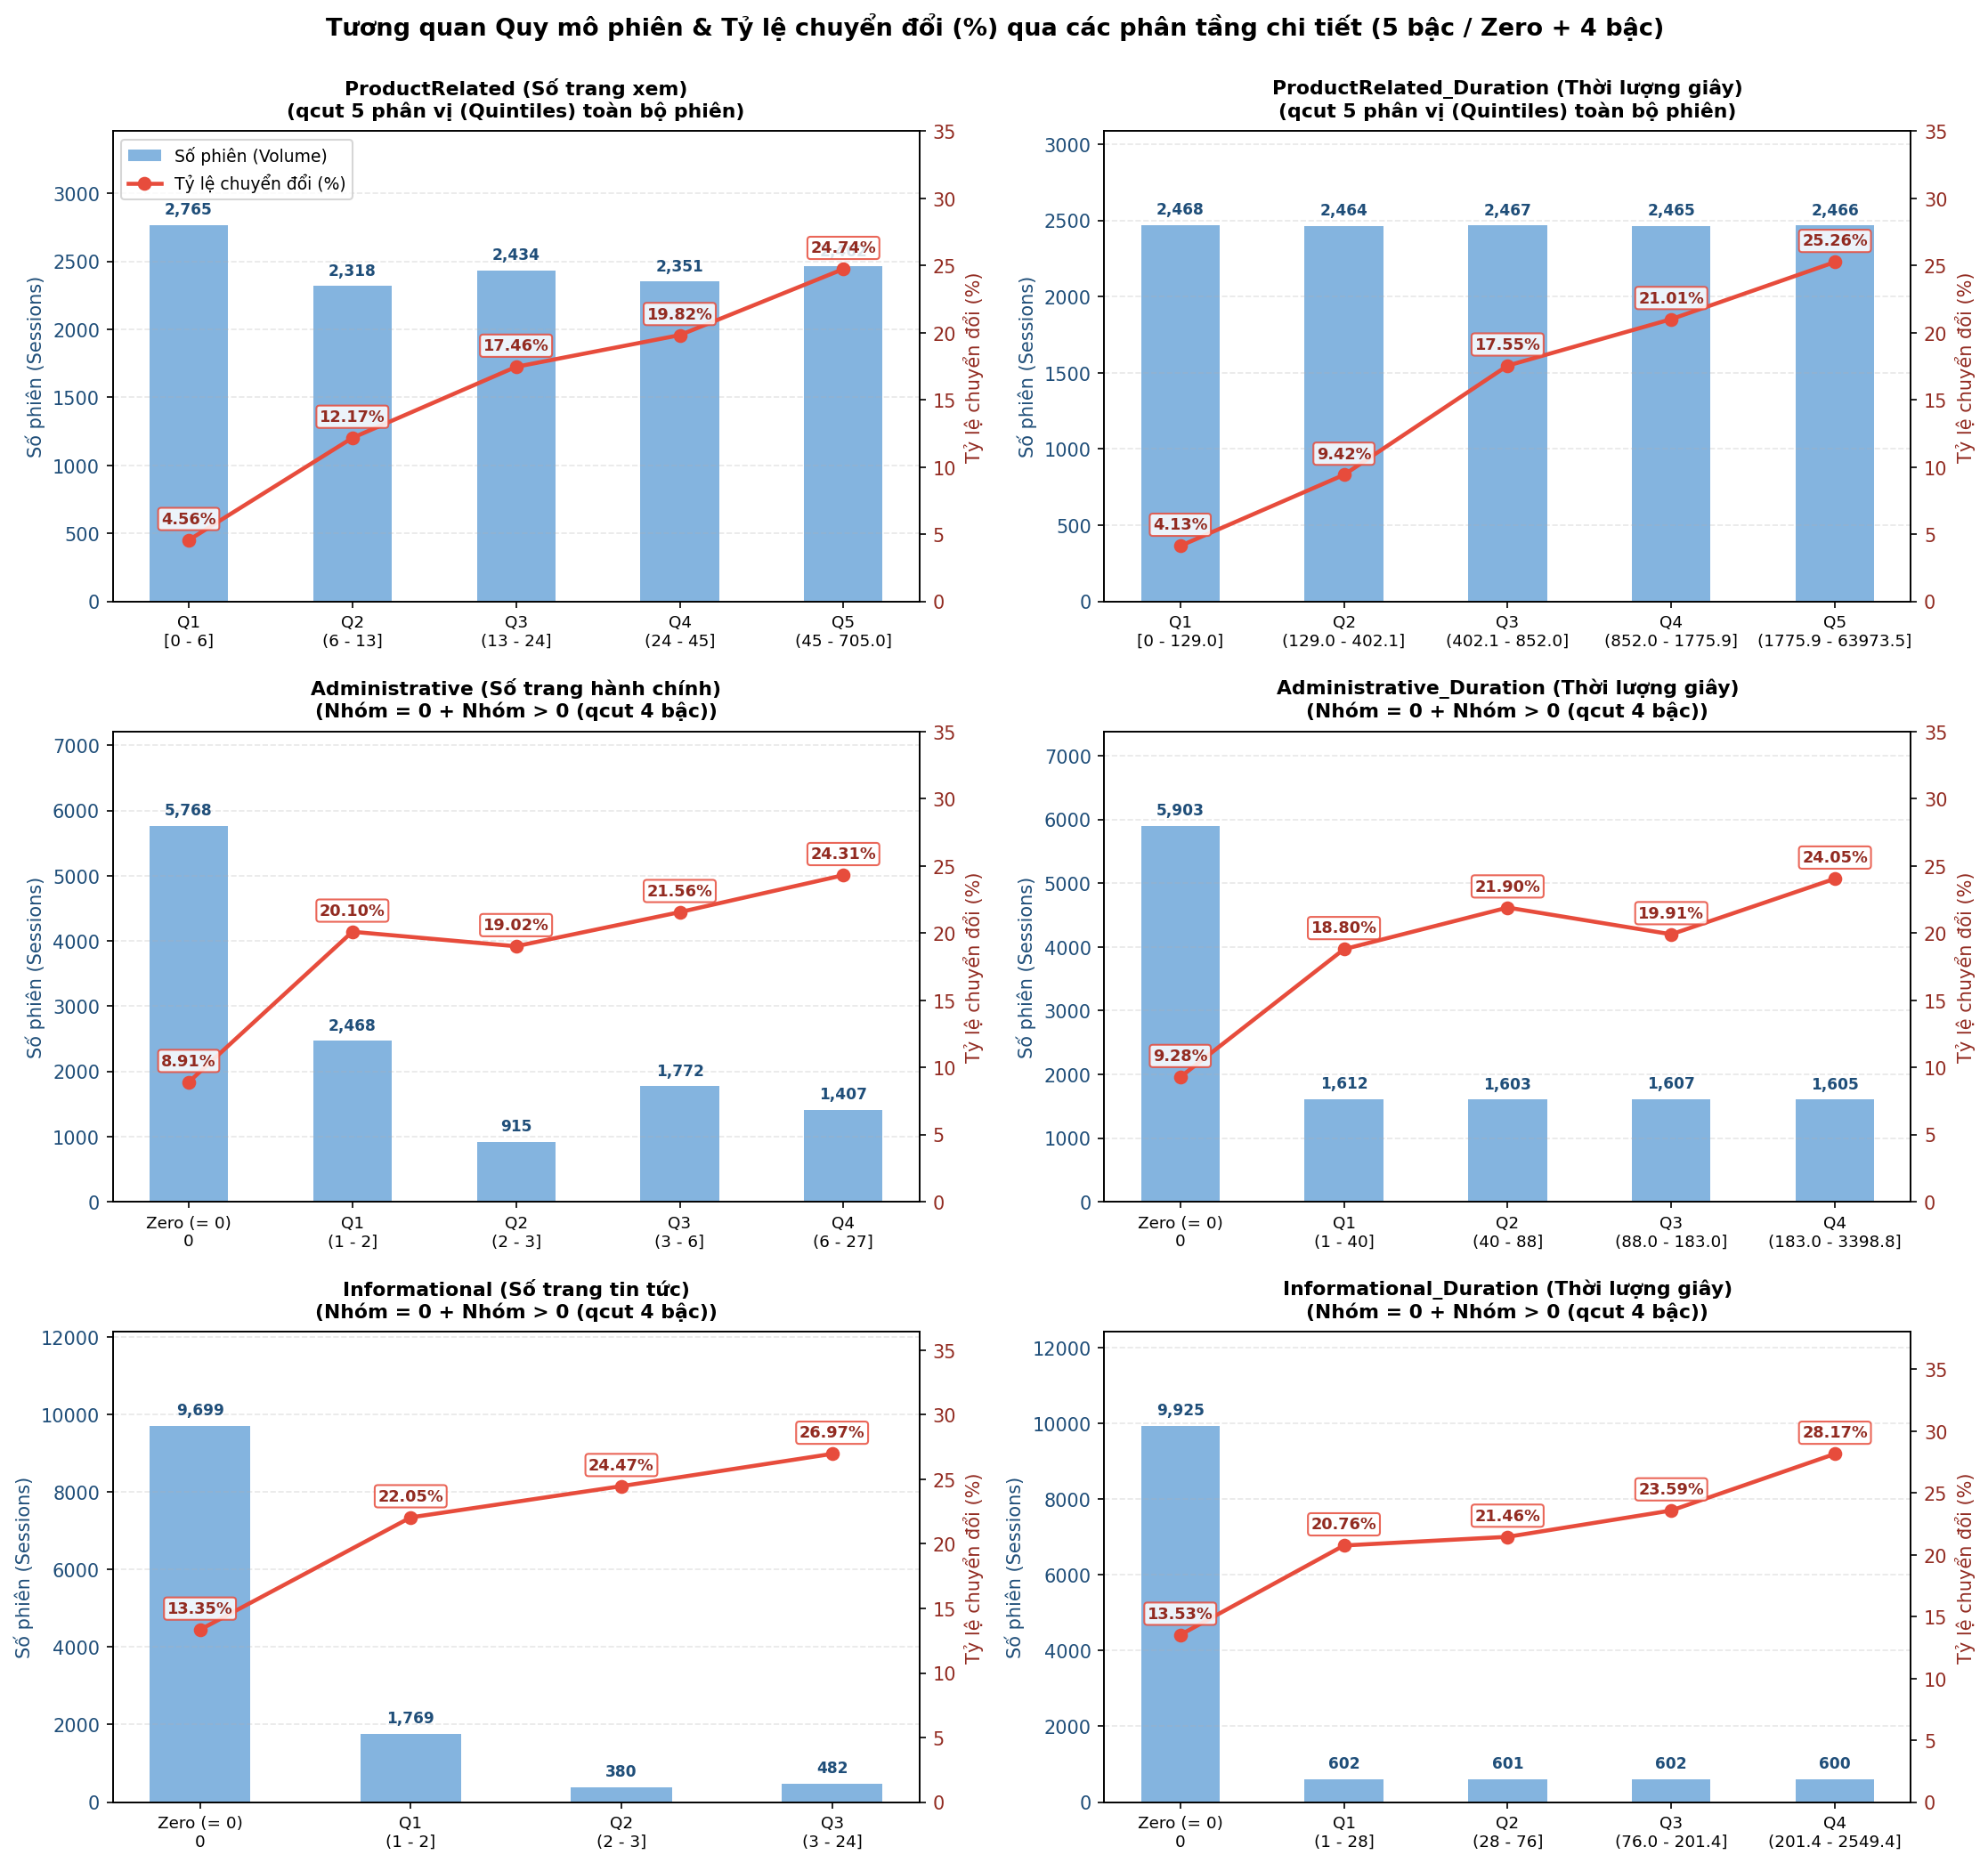

In [11]:
page_dur_cols = [
    'ProductRelated', 'ProductRelated_Duration',
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration'
]

# 1. Bảng so sánh Median và Mean giữa 2 nhóm Revenue
comp_median = df.groupby('Revenue')[page_dur_cols].median().T
comp_mean = df.groupby('Revenue')[page_dur_cols].mean().T
comp_summary = pd.DataFrame({
    'Median (False)': comp_median[False],
    'Median (True)': comp_median[True],
    'Tỷ lệ tăng Median': (comp_median[True] / comp_median[False].replace(0, np.nan)).round(2),
    'Mean (False)': comp_mean[False].round(2),
    'Mean (True)': comp_mean[True].round(2)
})
print("=== SO SÁNH GIÁ TRỊ TRUNG VỊ VÀ TRUNG BÌNH THEO REVENUE ===")
display(comp_summary)

# 2. Phân tầng hành vi chi tiết theo qcut (5 bậc / Zero + 4 bậc) & Trực quan hóa tương quan Quy mô phiên - Tỷ lệ chuyển đổi
# Cấu hình phân tầng:
# - Cặp (Product, ProductDur): chia đều 5 phân vị (qcut 5 bậc / quintiles) trên toàn bộ phiên để mật độ phân bố đồng đều (~20% phiên/bậc).
# - Cặp (Admin, AdminDur) và (Info, InfoDur): tách nhóm = 0; riêng nhóm > 0 chia làm 4 phân vị (qcut 4 bậc / quartiles).
def get_binned_stats(df, col, split_zero=True, q=5):
    temp = df[[col, 'Revenue']].copy()
    if split_zero:
        pos_mask = temp[col] > 0
        pos_series = temp.loc[pos_mask, col]
        try:
            labels = [f'Q{i+1}' for i in range(q)]
            pos_cats, bins = pd.qcut(pos_series, q=q, labels=labels, retbins=True)
            cat_to_range = {}
            for i, lab in enumerate(labels):
                cat_to_range[lab] = f"({bins[i]:.1f} - {bins[i+1]:.1f}]" if bins[i+1] > 100 else f"({bins[i]:.0f} - {bins[i+1]:.0f}]"
        except ValueError:
            pos_cats, bins = pd.qcut(pos_series, q=q, duplicates='drop', retbins=True)
            n_bins = len(bins) - 1
            labels = [f'Q{i+1}' for i in range(n_bins)]
            pos_cats = pd.qcut(pos_series, q=q, labels=labels, duplicates='drop')
            cat_to_range = {}
            for i, lab in enumerate(labels):
                cat_to_range[lab] = f"({bins[i]:.0f} - {bins[i+1]:.0f}]"

        temp['Tier'] = 'Zero (= 0)'
        temp.loc[pos_mask, 'Tier'] = pos_cats.astype(str)
        tier_order = ['Zero (= 0)'] + list(labels)
        cat_to_range['Zero (= 0)'] = '0'
    else:
        labels = [f'Q{i+1}' for i in range(q)]
        temp['Tier'], bins = pd.qcut(temp[col], q=q, labels=labels, retbins=True)
        tier_order = labels
        cat_to_range = {}
        for i, lab in enumerate(labels):
            fmt = ".1f" if bins[i+1] > 100 else (".0f" if bins[i+1] == int(bins[i+1]) else ".1f")
            left_fmt = ".1f" if bins[i] > 100 else ".0f"
            cat_to_range[lab] = f"[{bins[i]:{left_fmt}} - {bins[i+1]:{fmt}}]" if i == 0 else f"({bins[i]:{left_fmt}} - {bins[i+1]:{fmt}}]"

    temp['Tier'] = pd.Categorical(temp['Tier'], categories=tier_order, ordered=True)
    stats = temp.groupby('Tier', observed=True)['Revenue'].agg(
        sessions='size',
        conversions='sum',
        cr='mean'
    ).reset_index()
    stats['cr_pct'] = (stats['cr'] * 100).round(2)
    stats['Range'] = stats['Tier'].map(cat_to_range)
    return stats

cols_config = [
    ('ProductRelated', False, 5, 'ProductRelated (Số trang xem)', 'qcut 5 phân vị (Quintiles) toàn bộ phiên'),
    ('ProductRelated_Duration', False, 5, 'ProductRelated_Duration (Thời lượng giây)', 'qcut 5 phân vị (Quintiles) toàn bộ phiên'),
    ('Administrative', True, 4, 'Administrative (Số trang hành chính)', 'Nhóm = 0 + Nhóm > 0 (qcut 4 bậc)'),
    ('Administrative_Duration', True, 4, 'Administrative_Duration (Thời lượng giây)', 'Nhóm = 0 + Nhóm > 0 (qcut 4 bậc)'),
    ('Informational', True, 4, 'Informational (Số trang tin tức)', 'Nhóm = 0 + Nhóm > 0 (qcut 4 bậc)'),
    ('Informational_Duration', True, 4, 'Informational_Duration (Thời lượng giây)', 'Nhóm = 0 + Nhóm > 0 (qcut 4 bậc)')
]

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

color_bar = '#5B9BD5'
color_line = '#E74C3C'

for idx, (col, split_0, q_val, title, subtitle) in enumerate(cols_config):
    ax1 = axes[idx]
    stats = get_binned_stats(df, col, split_zero=split_0, q=q_val)
    
    x_labels = [f"{row['Tier']}\n{row['Range']}" for _, row in stats.iterrows()]
    x_pos = range(len(stats))
    
    # Cột thể hiện số lượng phiên (Volume) trên trục Y bên trái
    bars = ax1.bar(x_pos, stats['sessions'], color=color_bar, alpha=0.75, width=0.48, label='Số phiên (Volume)')
    ax1.set_ylabel('Số phiên (Sessions)', color='#1F4E79', fontsize=10)
    ax1.tick_params(axis='y', labelcolor='#1F4E79')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, fontsize=8.8)
    max_sess = stats['sessions'].max()
    ax1.set_ylim(0, max_sess * 1.25)
    ax1.grid(axis='y', linestyle='--', alpha=0.3)
    
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + max_sess * 0.02, f'{h:,}', ha='center', va='bottom', fontsize=8.2, color='#1F4E79', fontweight='bold')

    # Đường thể hiện Tỷ lệ chuyển đổi (%) trên trục Y bên phải
    ax2 = ax1.twinx()
    ax2.plot(x_pos, stats['cr_pct'], color=color_line, marker='o', linewidth=2.2, markersize=6.5, label='Tỷ lệ chuyển đổi (%)')
    ax2.set_ylabel('Tỷ lệ chuyển đổi (%)', color='#922B21', fontsize=10)
    ax2.tick_params(axis='y', labelcolor='#922B21')
    ax2.set_ylim(0, max(35, stats['cr_pct'].max() * 1.35))
    
    for x_i, y_val in enumerate(stats['cr_pct']):
        ax2.annotate(
            f'{y_val:.2f}%',
            (x_i, y_val),
            textcoords='offset points',
            xytext=(0, 9),
            ha='center',
            fontsize=8.5,
            fontweight='bold',
            color='#922B21',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor=color_line, alpha=0.85)
        )
        
    ax1.set_title(f"{title}\n({subtitle})", fontsize=10.5, fontweight='bold', pad=8)
    
    if idx == 0:
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9, frameon=True)

plt.suptitle('Tương quan Quy mô phiên & Tỷ lệ chuyển đổi (%) qua các phân tầng chi tiết (5 bậc / Zero + 4 bậc)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

#### 3.1.2. Mối quan hệ giữa Tỷ lệ thoát (BounceRates, ExitRates) và Tỷ lệ chuyển đổi
Kiểm chứng 2 câu hỏi trọng tâm:
1. **Phân phối tổng thể**: Khách chốt đơn (`Revenue = True`) có tỷ lệ thoát (`ExitRates`) và nảy trang (`BounceRates`) thấp hơn nhóm không mua không?
2. **Quy luật suy giảm chuyển đổi**: Khi rời rạc hóa các tỷ lệ này thành các phân tầng (Tiers), tỷ lệ chuyển đổi (`Conversion Rate`) suy giảm như thế nào qua từng bậc?


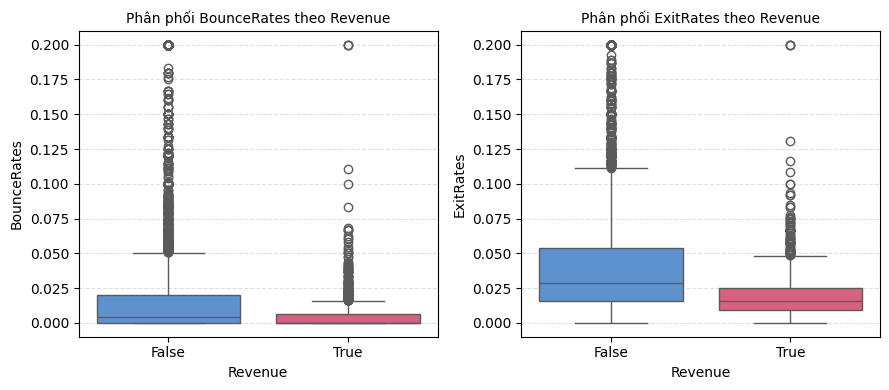

=== 1. BẢNG THỐNG KÊ PHÂN VỊ CỦA EXITRATES VÀ BOUNCERATES THEO REVENUE ===


Revenue,False,True
ExitRates (Median),0.0286,0.0160
ExitRates (Q3 - 75%),0.0538,0.0250
ExitRates (Mean),0.0474,0.0196
BounceRates (Median),0.0043,0.0000
BounceRates (Q3 - 75%),0.0200,0.0065
BounceRates (Mean),0.0253,0.0051


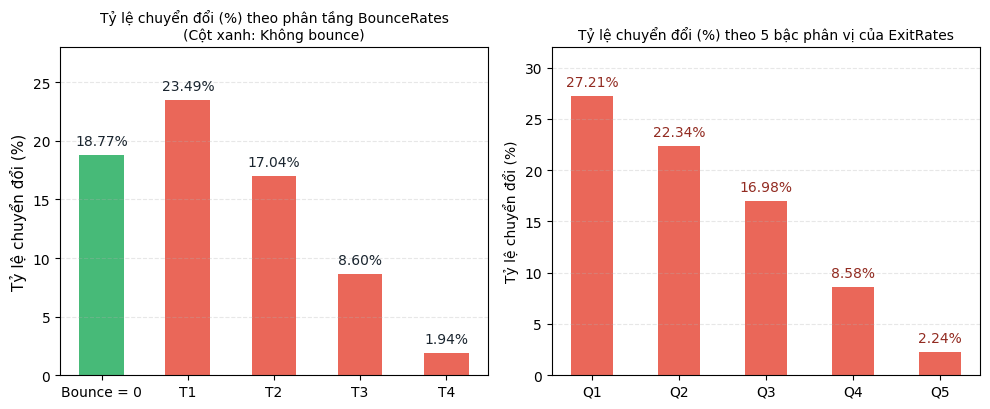

=== 2. TỶ LỆ CHUYỂN ĐỔI THEO PHÂN TẦNG LAI CỦA BOUNCERATES ===


,sessions,conversions,conversion_rate_pct
BounceRates_Tier,,,
Bounce = 0,5518,1036,18.77
T1,1707,401,23.49
T2,1719,293,17.04
T3,1687,145,8.60
T4,1699,33,1.94



=== 3. TỶ LỆ CHUYỂN ĐỔI THEO 5 BẬC NGŨ PHÂN VỊ CỦA EXITRATES ===


,sessions,conversions,conversion_rate_pct
ExitRates_Tier,,,
Q1,2466,671,27.21
Q2,2471,552,22.34
Q3,2461,418,16.98
Q4,2472,212,8.58
Q5,2460,55,2.24


In [ ]:
# 1. Boxplot BounceRates và ExitRates theo Revenue
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

sns.boxplot(data=df, x='Revenue', y='BounceRates', ax=axes[0], palette=['#4A90E2', '#E94E77'], hue='Revenue', legend=False)
axes[0].set_title('Phân phối BounceRates theo Revenue', fontsize=10)
axes[0].set_ylabel('BounceRates')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

sns.boxplot(data=df, x='Revenue', y='ExitRates', ax=axes[1], palette=['#4A90E2', '#E94E77'], hue='Revenue', legend=False)
axes[1].set_title('Phân phối ExitRates theo Revenue', fontsize=10)
axes[1].set_ylabel('ExitRates')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 2. Bảng số liệu chi tiết cấu thành Boxplot (Median, Q3 - 75%, Mean)
rates_stat = pd.DataFrame({
    'ExitRates (Median)': df.groupby('Revenue')['ExitRates'].median(),
    'ExitRates (Q3 - 75%)': df.groupby('Revenue')['ExitRates'].quantile(0.75),
    'ExitRates (Mean)': df.groupby('Revenue')['ExitRates'].mean(),
    'BounceRates (Median)': df.groupby('Revenue')['BounceRates'].median(),
    'BounceRates (Q3 - 75%)': df.groupby('Revenue')['BounceRates'].quantile(0.75),
    'BounceRates (Mean)': df.groupby('Revenue')['BounceRates'].mean()
}).T.round(4)

print("=== 1. BẢNG THỐNG KÊ PHÂN VỊ CỦA EXITRATES VÀ BOUNCERATES THEO REVENUE ===")
display(rates_stat)

# 3. Rời rạc hoá (Discretization) để đo lường quy luật suy giảm tỷ lệ chuyển đổi
# 3.1. BounceRates: Chiến lược lai (Nhóm Zero = 0 + 4 tứ phân vị nhóm > 0)
bounce_pos = df[df['BounceRates'] > 0].copy()
bounce_pos_labels = ['T1', 'T2', 'T3', 'T4']
bounce_pos['Pos_Tier'] = pd.qcut(bounce_pos['BounceRates'], q=4, labels=bounce_pos_labels)

df['BounceRates_Tier'] = 'Bounce = 0'
df.loc[df['BounceRates'] > 0, 'BounceRates_Tier'] = bounce_pos['Pos_Tier'].astype(str)

bounce_order = ['Bounce = 0', 'T1', 'T2', 'T3', 'T4']
df['BounceRates_Tier'] = pd.Categorical(df['BounceRates_Tier'], categories=bounce_order, ordered=True)

bounce_tier_stats = (
    df.groupby('BounceRates_Tier', observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
bounce_tier_stats['conversion_rate_pct'] = (bounce_tier_stats['conversion_rate'] * 100).round(2)
bounce_tier_stats.drop(columns=['conversion_rate'], inplace=True)

# 3.2. ExitRates: Ngũ phân vị (5 quintiles bằng nhau, mỗi bậc ~20% phiên)
exit_labels = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
df['ExitRates_Tier'] = pd.qcut(df['ExitRates'], q=5, labels=exit_labels)

exit_tier_stats = (
    df.groupby('ExitRates_Tier', observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
exit_tier_stats['conversion_rate_pct'] = (exit_tier_stats['conversion_rate'] * 100).round(2)
exit_tier_stats.drop(columns=['conversion_rate'], inplace=True)

# 4. Trực quan hóa mối quan hệ nghịch biến qua biểu đồ bậc thang tỷ lệ chuyển đổi
# Trái: BounceRates (Cột Zero màu xanh), Phải: ExitRates
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

base_color = '#E74C3C'
bounce_zero_color = '#27AE60'
bounce_colors = [bounce_zero_color] + [base_color] * 4

# Subplot 0 (Trái): BounceRates Tiers
bars_bounce = axes[0].bar(bounce_tier_stats['BounceRates_Tier'], bounce_tier_stats['conversion_rate_pct'], color=bounce_colors, alpha=0.85, width=0.52)
axes[0].set_title('Tỷ lệ chuyển đổi (%) theo phân tầng BounceRates\n(Cột xanh: Không bounce)', fontsize=10)
axes[0].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=11)
axes[0].set_ylim(0, 28)
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

for bar in bars_bounce:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, color='#1A252F')

# Subplot 1 (Phải): ExitRates Tiers
bars_exit = axes[1].bar(exit_tier_stats['ExitRates_Tier'], exit_tier_stats['conversion_rate_pct'], color=base_color, alpha=0.85, width=0.48)
axes[1].set_title('Tỷ lệ chuyển đổi (%) theo 5 bậc phân vị của ExitRates', fontsize=10)
axes[1].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=10)
axes[1].set_ylim(0, 32)
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

for bar in bars_exit:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.7, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, color='#922B21')

plt.tight_layout()
plt.show()

# 5. In bảng thống kê chi tiết quy mô phiên và tỷ lệ chuyển đổi
print("=== 2. TỶ LỆ CHUYỂN ĐỔI THEO PHÂN TẦNG LAI CỦA BOUNCERATES ===")
display(bounce_tier_stats.set_index('BounceRates_Tier'))

print("\n=== 3. TỶ LỆ CHUYỂN ĐỔI THEO 5 BẬC NGŨ PHÂN VỊ CỦA EXITRATES ===")
display(exit_tier_stats.set_index('ExitRates_Tier'))

#### 3.1.3. Phân tích đặc trưng hành vi trên trang: `PageValues`
 Phân tích mối tương quan giữa **số phiên** và **Tỷ lệ chuyển đổi (%)** qua biểu đồ trục kép, phân phối thống kê của nhóm có giá trị trang `PageValues > 0`

=== 1. QUY MÔ PHIÊN & TỶ LỆ CHUYỂN ĐỔI THEO BẬC PAGEVALUES (QCUT) ===


,sessions,conversions,conversion_rate_pct,Dải giá trị (Range)
PageValues_Tier,,,,
Zero (PV = 0),9600,370,3.85,0.00
Low,910,347,38.13,"(0.04, 9.73]"
Medium,910,501,55.05,"(9.73, 26.98]"
High,910,690,75.82,"(26.98, 361.76]"



=== 2. THỐNG KÊ CHI TIẾT PAGEVALUES (NHÓM PV > 0) THEO KẾT QUẢ MUA HÀNG ===


,count,mean,std,min,q1,median,q3,iqr,max
Revenue,,,,,,,,,
False,1192,17.28,21.35,0.04,5.04,10.46,21.16,16.12,246.76
True,1538,33.82,36.26,0.07,10.79,22.97,45.56,34.77,361.76


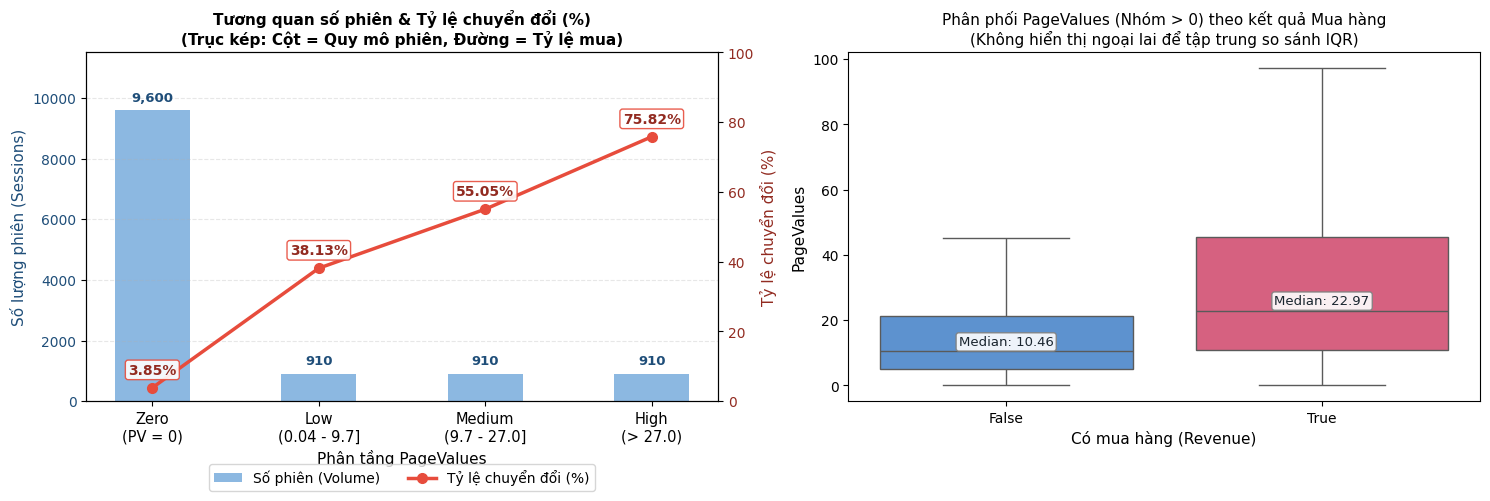

In [ ]:
# 1. Tách riêng PageValues = 0 và phân tầng nhóm > 0 bằng qcut (Tertiles: 3 phần bằng nhau)
pos_mask = df['PageValues'] > 0
pos_df = df[pos_mask].copy()

pos_labels = ['Low', 'Medium', 'High']
pos_df['PageValues_Tier'] = pd.qcut(pos_df['PageValues'], q=3, labels=pos_labels)

df['PageValues_Tier'] = 'Zero (PV = 0)'
df.loc[pos_mask, 'PageValues_Tier'] = pos_df['PageValues_Tier'].astype(str)

tier_order = ['Zero (PV = 0)', 'Low', 'Medium', 'High']
df['PageValues_Tier'] = pd.Categorical(df['PageValues_Tier'], categories=tier_order, ordered=True)

tier_stats = (
    df.groupby('PageValues_Tier', observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
tier_stats['conversion_rate_pct'] = (tier_stats['conversion_rate'] * 100).round(2)
tier_stats.drop(columns=['conversion_rate'], inplace=True)

# Ánh xạ dải giá trị chi tiết của từng phân tầng
pv_intervals = pd.qcut(df.loc[pos_mask, 'PageValues'], q=3).unique().sort_values()
interval_map = {'Zero (PV = 0)': '0.00'}
for label, interval in zip(pos_labels, pv_intervals):
    interval_map[label] = f"({interval.left:.2f}, {interval.right:.2f}]"
tier_stats['Dải giá trị (Range)'] = tier_stats['PageValues_Tier'].map(interval_map)

print("=== 1. QUY MÔ PHIÊN & TỶ LỆ CHUYỂN ĐỔI THEO BẬC PAGEVALUES (QCUT) ===")
display(tier_stats.set_index('PageValues_Tier'))

# 2. Thống kê chi tiết Q1, Median, Q3, Mean, IQR cho nhóm PV > 0 theo Revenue
pos_stats = df[pos_mask].groupby('Revenue')['PageValues'].agg(
    count='count',
    mean='mean',
    std='std',
    min='min',
    q1=lambda x: x.quantile(0.25),
    median='median',
    q3=lambda x: x.quantile(0.75),
    max='max'
)
pos_stats['iqr'] = pos_stats['q3'] - pos_stats['q1']
pos_stats = pos_stats.round(2)

print("\n=== 2. THỐNG KÊ CHI TIẾT PAGEVALUES (NHÓM PV > 0) THEO KẾT QUẢ MUA HÀNG ===")
display(pos_stats[['count', 'mean', 'std', 'min', 'q1', 'median', 'q3', 'iqr', 'max']])

# 3. Biểu đồ trực quan hóa kết hợp (1x2 Subplots)
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(15, 5.2))

# Subplot 1: Biểu đồ trục kép (Dual-Axis) với nhãn 2 dòng kèm dải giá trị chi tiết
tier_labels_display = [
    'Zero\n(PV = 0)',
    'Low\n(0.04 - 9.7]',
    'Medium\n(9.7 - 27.0]',
    'High\n(> 27.0)'
]

color_bar = '#5B9BD5'
bars = ax1.bar(range(len(tier_stats)), tier_stats['sessions'], color=color_bar, alpha=0.7, width=0.45, label='Số phiên (Volume)')
ax1.set_ylabel('Số lượng phiên (Sessions)', color='#1F4E79', fontsize=11)
ax1.set_xlabel('Phân tầng PageValues', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#1F4E79')
ax1.set_xticks(range(len(tier_stats)))
ax1.set_xticklabels(tier_labels_display, fontsize=10.5)
ax1.set_ylim(0, 11500)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 200, f'{yval:,}', ha='center', va='bottom', fontsize=9.5, color='#1F4E79', fontweight='bold')

ax2 = ax1.twinx()
color_line = '#E74C3C'
line = ax2.plot(range(len(tier_stats)), tier_stats['conversion_rate_pct'], color=color_line, marker='o', linewidth=2.5, markersize=7, label='Tỷ lệ chuyển đổi (%)')
ax2.set_ylabel('Tỷ lệ chuyển đổi (%)', color='#922B21', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#922B21')
ax2.set_ylim(0, 100)

for x_idx, y in enumerate(tier_stats['conversion_rate_pct']):
    ax2.annotate(f'{y:.2f}%', (x_idx, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=10, fontweight='bold', color='#922B21',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#E74C3C', alpha=0.9))

ax1.set_title('Tương quan số phiên & Tỷ lệ chuyển đổi (%)\n(Trục kép: Cột = Quy mô phiên, Đường = Tỷ lệ mua)', fontsize=11, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=True)

# Subplot 2: Phân phối PageValues của nhóm Positive (> 0) giữa Mua vs Không Mua
sns.boxplot(
    data=df[pos_mask],
    x='Revenue',
    y='PageValues',
    ax=ax3,
    palette=['#4A90E2', '#E94E77'],
    hue='Revenue',
    legend=False,
    showfliers=False
)
ax3.set_title('Phân phối PageValues (Nhóm > 0) theo kết quả Mua hàng\n(Không hiển thị ngoại lai để tập trung so sánh IQR)', fontsize=11)
ax3.set_xlabel('Có mua hàng (Revenue)', fontsize=11)
ax3.set_ylabel('PageValues', fontsize=11)

for i, (rev, row) in enumerate(pos_stats.iterrows()):
    ax3.text(i, row['median'] + 1.8, f"Median: {row['median']:.2f}", ha='center', color='#1A252F', fontsize=9.5,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='gray', alpha=0.9))

plt.tight_layout()
plt.show()

### 3.2. Nhóm khách hàng & Bối cảnh nào có tỷ lệ chuyển đổi cao nhất?
#### 3.2.1a. Đo lường tỷ lệ chuyển đổi theo Bối cảnh & Khách hàng: Loại khách, Tháng, Cuối tuần và Ngày lễ
Khảo sát mối tương quan giữa **số phiên (Volume)** và **tỷ lệ chuyển đổi (%)** qua biểu đồ trục kép trên 4 chiều vĩ mô: Loại khách (`VisitorType`), Mùa vụ (`Month`), Ngày trong tuần (`Weekend`) và Độ cận kề ngày lễ (`SpecialDay`).


=== 1. CONVERSION RATE THEO VISITOR TYPE ===


,sessions,conversions,conversion_rate_pct
VisitorType,,,
New_Visitor,1694,422,24.91
Other,85,16,18.82
Returning_Visitor,10551,1470,13.93



=== 2. CONVERSION RATE THEO MONTH (TRÌNH TỰ MÙA VỤ) ===


,sessions,conversions,conversion_rate_pct
Month,,,
Feb,184,3,1.63
Mar,1907,192,10.07
May,3364,365,10.85
June,288,29,10.07
Jul,432,66,15.28
Aug,433,76,17.55
Sep,448,86,19.20
Oct,549,115,20.95
Nov,2998,760,25.35



=== 3. CONVERSION RATE THEO WEEKEND (NGÀY THƯỜNG VS CUỐI TUẦN) ===


,sessions,conversions,conversion_rate_pct
Weekend,,,
False,9462,1409,14.89
True,2868,499,17.40



=== 4. CONVERSION RATE THEO SPECIAL DAY (ĐỘ GẦN NGÀY LỄ) ===


,sessions,conversions,conversion_rate_pct
SpecialDay,,,
0.0,11079,1831,16.53
0.2,178,14,7.87
0.4,243,13,5.35
0.6,351,29,8.26
0.8,325,11,3.38
1.0,154,10,6.49


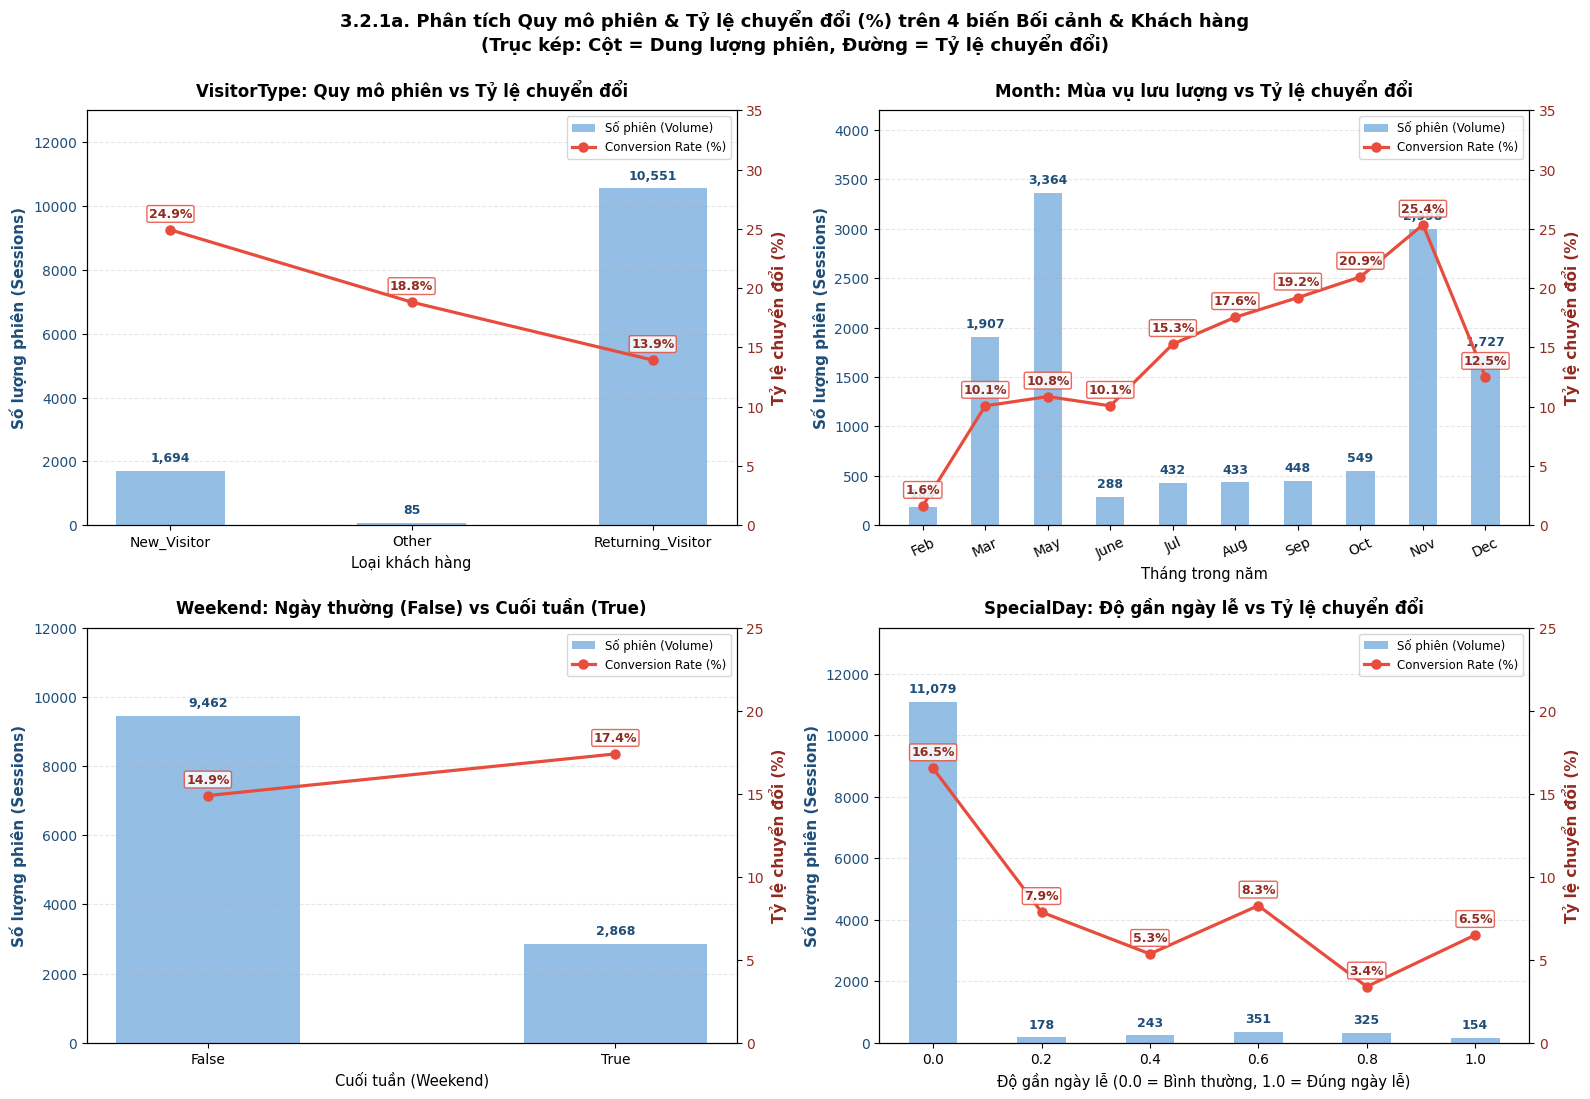

In [ ]:
def get_conversion_table(data, column, target='Revenue'):
    result = (
        data.groupby(column, observed=True)[target]
        .agg(sessions='size', conversions='sum', conversion_rate='mean')
    )
    result['conversion_rate_pct'] = (result['conversion_rate'] * 100).round(2)
    result.drop(columns=['conversion_rate'], inplace=True)
    return result

month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Chuẩn bị bảng thống kê cho cả 4 biến phân khúc
vt_data = get_conversion_table(df, 'VisitorType')
m_data = get_conversion_table(df, 'Month').reindex(month_order)
w_data = get_conversion_table(df, 'Weekend')
sd_data = get_conversion_table(df, 'SpecialDay')

# In đầy đủ bảng thống kê của 4 biến
print("=== 1. CONVERSION RATE THEO VISITOR TYPE ===")
display(vt_data)

print("\n=== 2. CONVERSION RATE THEO MONTH (TRÌNH TỰ MÙA VỤ) ===")
display(m_data)

print("\n=== 3. CONVERSION RATE THEO WEEKEND (NGÀY THƯỜNG VS CUỐI TUẦN) ===")
display(w_data)

print("\n=== 4. CONVERSION RATE THEO SPECIAL DAY (ĐỘ GẦN NGÀY LỄ) ===")
display(sd_data)

# Trực quan hóa lưới 2x2 bằng biểu đồ trục kép (Dual-Axis: Cột = Volume, Đường = Conversion Rate %)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

def plot_dual_axis(ax, data, title, xlabel, bar_color='#5B9BD5', line_color='#E74C3C', rot=0, max_y1=None, max_y2=35):
    x_labels = [str(x) for x in data.index]
    x_pos = range(len(x_labels))
    
    # Trục Y trái: Số lượng phiên (Volume)
    bars = ax.bar(x_pos, data['sessions'], color=bar_color, alpha=0.65, width=0.45, label='Số phiên (Volume)')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=rot)
    ax.set_ylabel('Số lượng phiên (Sessions)', color='#1F4E79', fontsize=11, fontweight='bold')
    ax.tick_params(axis='y', labelcolor='#1F4E79')
    if max_y1:
        ax.set_ylim(0, max_y1)
    else:
        ax.set_ylim(0, data['sessions'].max() * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + (ax.get_ylim()[1]*0.015), f'{int(h):,}', ha='center', va='bottom', fontsize=9, color='#1F4E79', fontweight='bold')
        
    # Trục Y phải: Tỷ lệ chuyển đổi (%)
    ax2 = ax.twinx()
    ax2.plot(x_pos, data['conversion_rate_pct'], color=line_color, marker='o', linewidth=2.3, markersize=6.5, label='Conversion Rate (%)')
    ax2.set_ylabel('Tỷ lệ chuyển đổi (%)', color='#922B21', fontsize=11, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#922B21')
    ax2.set_ylim(0, max_y2)
    
    for x, y in zip(x_pos, data['conversion_rate_pct']):
        ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#922B21',
                     bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor=line_color, alpha=0.85))
        
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontsize=10.5)
    
    # Ghép chú thích (legend)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True, fontsize=8.5)

plot_dual_axis(axes[0, 0], vt_data, 'VisitorType: Quy mô phiên vs Tỷ lệ chuyển đổi', 'Loại khách hàng', max_y1=13000, max_y2=35)
plot_dual_axis(axes[0, 1], m_data, 'Month: Mùa vụ lưu lượng vs Tỷ lệ chuyển đổi', 'Tháng trong năm', max_y1=4200, max_y2=35, rot=25)
plot_dual_axis(axes[1, 0], w_data, 'Weekend: Ngày thường (False) vs Cuối tuần (True)', 'Cuối tuần (Weekend)', max_y1=12000, max_y2=25)
plot_dual_axis(axes[1, 1], sd_data, 'SpecialDay: Độ gần ngày lễ vs Tỷ lệ chuyển đổi', 'Độ gần ngày lễ (0.0 = Bình thường, 1.0 = Đúng ngày lễ)', max_y1=13500, max_y2=25)

plt.suptitle('3.2.1a. Phân tích Quy mô phiên & Tỷ lệ chuyển đổi (%) trên 4 biến Bối cảnh & Khách hàng\n(Trục kép: Cột = Dung lượng phiên, Đường = Tỷ lệ chuyển đổi)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


#### 3.2.1b. Đo lường tỷ lệ chuyển đổi theo Kỹ thuật & Kênh truy cập: Nguồn lưu lượng, Hệ điều hành, Trình duyệt và Vùng địa lý
Khảo sát mối tương quan giữa **số phiên (Volume)** và **tỷ lệ chuyển đổi (%)** qua biểu đồ trục kép trên 4 chiều môi trường kỹ thuật: Kênh lưu lượng (`TrafficType`), Hệ điều hành (`OperatingSystems`), Trình duyệt (`Browser`) và Vùng địa lý (`Region`).


=== 1. CONVERSION RATE THEO TRAFFICTYPE (TOP 6 + OTHER) ===


,sessions,conversions,conversion_rate_pct
TrafficType,,,
2,3913,847,21.65
1,2451,262,10.69
3,2052,180,8.77
4,1069,165,15.43
13,738,43,5.83
10,450,90,20.00
Other,1657,321,19.37



=== 2. CONVERSION RATE THEO OPERATING SYSTEMS (TOP 4 + OTHER) ===


,sessions,conversions,conversion_rate_pct
OperatingSystems,,,
2,6601,1155,17.50
1,2585,379,14.66
3,2555,268,10.49
4,478,85,17.78
Other,111,21,18.92



=== 3. CONVERSION RATE THEO BROWSER (TOP 4 + OTHER) ===


,sessions,conversions,conversion_rate_pct
Browser,,,
2,7961,1223,15.36
1,2462,365,14.83
4,736,130,17.66
5,467,86,18.42
Other,704,104,14.77



=== 4. CONVERSION RATE THEO 9 REGIONS ===


,sessions,conversions,conversion_rate_pct
Region,,,
1,4780,771,16.13
3,2403,349,14.52
4,1182,175,14.81
2,1136,188,16.55
6,805,112,13.91
7,761,119,15.64
9,511,86,16.83
8,434,56,12.90
5,318,52,16.35


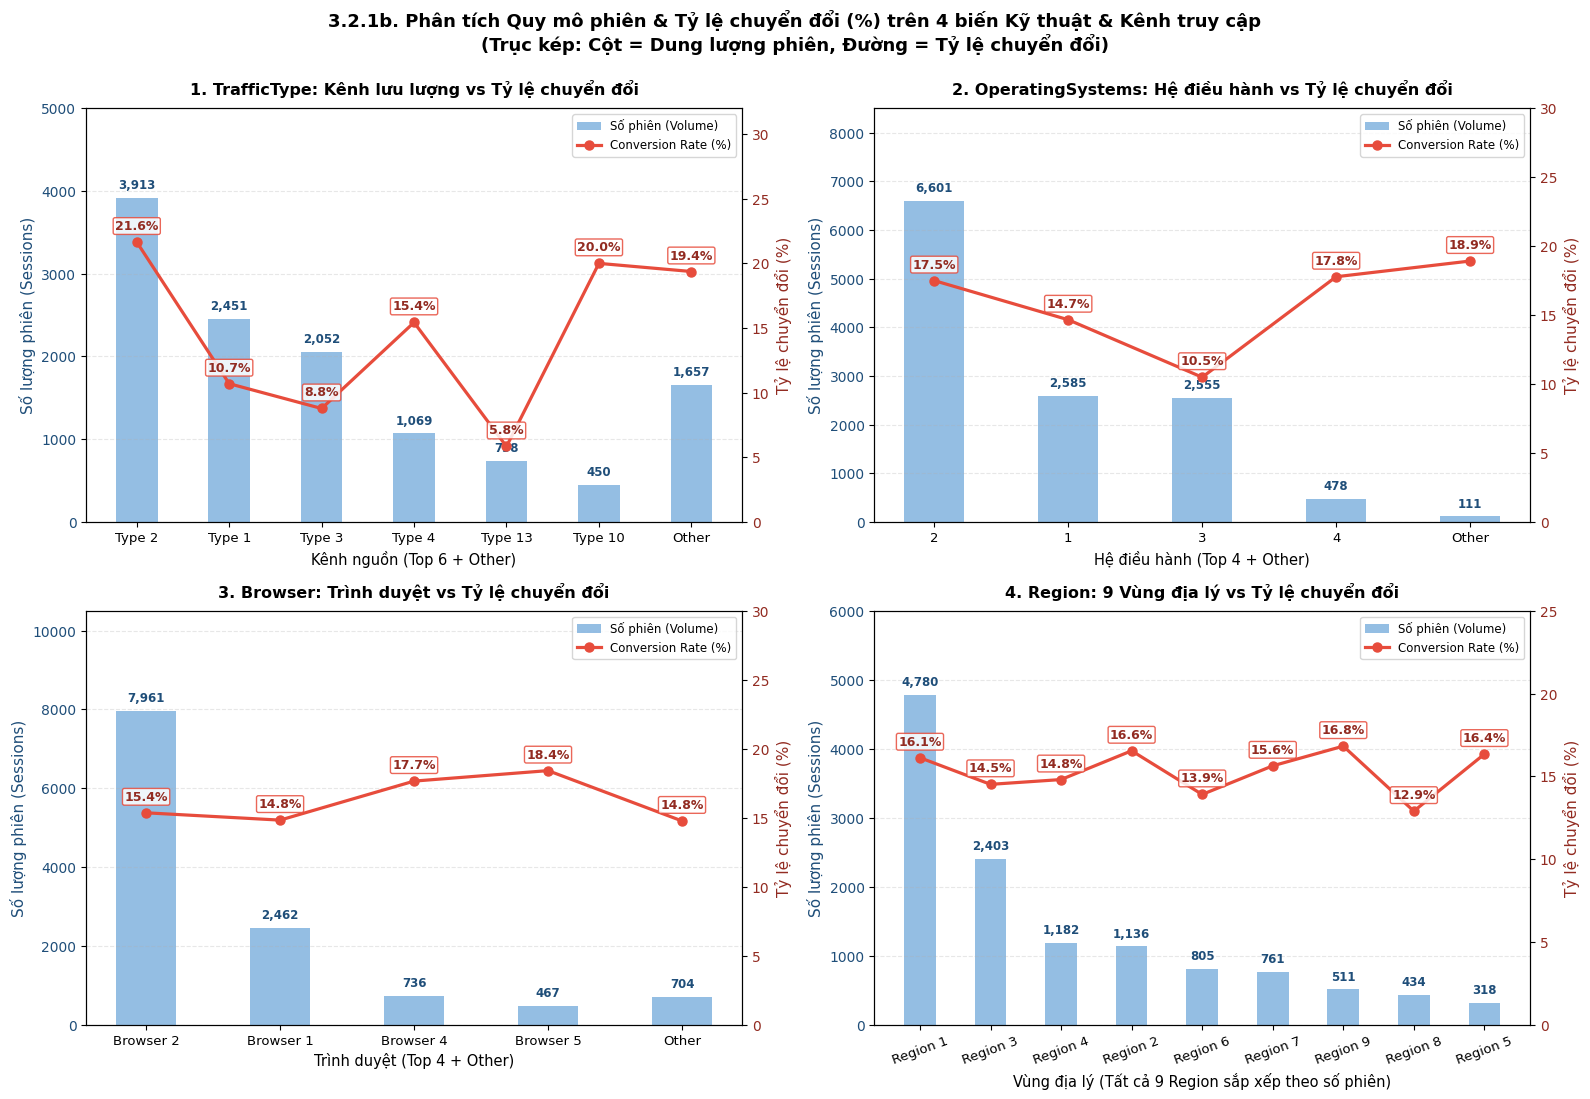

In [ ]:
# 1. Hàm tính toán bảng thống kê phiên và tỷ lệ chuyển đổi
def get_bivariate_table(data, column, top_n=None, target='Revenue'):
    s = data.groupby(column, observed=True)[target].agg(
        sessions='size', conversions='sum', conversion_rate='mean'
    )
    s['conversion_rate_pct'] = (s['conversion_rate'] * 100).round(2)
    s.drop(columns=['conversion_rate'], inplace=True)
    s = s.sort_values('sessions', ascending=False)
    
    if top_n and len(s) > top_n:
        top = s.iloc[:top_n].copy()
        other = s.iloc[top_n:].sum()
        other_cr = (other['conversions'] / other['sessions'] * 100).round(2)
        top.loc['Other'] = [int(other['sessions']), int(other['conversions']), other_cr]
        top['sessions'] = top['sessions'].astype(int)
        top['conversions'] = top['conversions'].astype(int)
        return top
    return s

# 2. Chuẩn bị dữ liệu cho 4 biến Kỹ thuật & Kênh lưu lượng
traffic_df = get_bivariate_table(df, 'TrafficType', top_n=6)
os_df = get_bivariate_table(df, 'OperatingSystems', top_n=4)
browser_df = get_bivariate_table(df, 'Browser', top_n=4)
region_df = get_bivariate_table(df, 'Region')  # Hiển thị cả 9 vùng địa lý theo thứ tự session giảm dần

print("=== 1. CONVERSION RATE THEO TRAFFICTYPE (TOP 6 + OTHER) ===")
display(traffic_df)

print("\n=== 2. CONVERSION RATE THEO OPERATING SYSTEMS (TOP 4 + OTHER) ===")
display(os_df)

print("\n=== 3. CONVERSION RATE THEO BROWSER (TOP 4 + OTHER) ===")
display(browser_df)

print("\n=== 4. CONVERSION RATE THEO 9 REGIONS ===")
display(region_df)

# 3. Trực quan hóa lưới 2x2 biểu đồ trục kép (Dual-Axis)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

def plot_dual_axis_custom(ax, data, title, xlabel, bar_color='#5B9BD5', line_color='#E74C3C', rot=0, max_y1=None, max_y2=35):
    x_labels = [f"Type {x}" if str(x).isdigit() and 'Traffic' in title else (f"OS {x}" if str(x).isdigit() and 'OS' in title else (f"Browser {x}" if str(x).isdigit() and 'Browser' in title else (f"Region {x}" if str(x).isdigit() and 'Region' in title else str(x)))) for x in data.index]
    x_pos = range(len(x_labels))
    
    bars = ax.bar(x_pos, data['sessions'], color=bar_color, alpha=0.65, width=0.45, label='Số phiên (Volume)')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=rot, fontsize=9.5)
    ax.set_ylabel('Số lượng phiên (Sessions)', color='#1F4E79', fontsize=11)
    ax.tick_params(axis='y', labelcolor='#1F4E79')
    if max_y1:
        ax.set_ylim(0, max_y1)
    else:
        ax.set_ylim(0, data['sessions'].max() * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + (ax.get_ylim()[1]*0.015), f'{int(h):,}',
                ha='center', va='bottom', fontsize=8.5, color='#1F4E79', fontweight='bold')
        
    ax2 = ax.twinx()
    ax2.plot(x_pos, data['conversion_rate_pct'], color=line_color, marker='o', linewidth=2.3, markersize=6.5, label='Conversion Rate (%)')
    ax2.set_ylabel('Tỷ lệ chuyển đổi (%)', color='#922B21', fontsize=11)
    ax2.tick_params(axis='y', labelcolor='#922B21')
    ax2.set_ylim(0, max_y2)
    
    for x, y in zip(x_pos, data['conversion_rate_pct']):
        ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#922B21',
                     bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor=line_color, alpha=0.85))
        
    ax.set_title(title, fontsize=11.5, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontsize=10.5)
    
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True, fontsize=8.5)

plot_dual_axis_custom(axes[0, 0], traffic_df, '1. TrafficType: Kênh lưu lượng vs Tỷ lệ chuyển đổi', 'Kênh nguồn (Top 6 + Other)', max_y1=5000, max_y2=32)
plot_dual_axis_custom(axes[0, 1], os_df, '2. OperatingSystems: Hệ điều hành vs Tỷ lệ chuyển đổi', 'Hệ điều hành (Top 4 + Other)', max_y1=8500, max_y2=30)
plot_dual_axis_custom(axes[1, 0], browser_df, '3. Browser: Trình duyệt vs Tỷ lệ chuyển đổi', 'Trình duyệt (Top 4 + Other)', max_y1=10500, max_y2=30)
plot_dual_axis_custom(axes[1, 1], region_df, '4. Region: 9 Vùng địa lý vs Tỷ lệ chuyển đổi', 'Vùng địa lý (Tất cả 9 Region sắp xếp theo số phiên)', max_y1=6000, max_y2=25, rot=20)

plt.suptitle('3.2.1b. Phân tích Quy mô phiên & Tỷ lệ chuyển đổi (%) trên 4 biến Kỹ thuật & Kênh truy cập\n(Trục kép: Cột = Dung lượng phiên, Đường = Tỷ lệ chuyển đổi)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


#### 3.2.2. Phân tích kết hợp: `Month × VisitorType`
Kiểm chứng 2 câu hỏi hành vi theo tháng:
1. **Tỷ lệ chuyển đổi (%)**: Khách mới `New_Visitor` có luôn mua nhiều hơn khách cũ `Returning_Visitor`, hay khoảng cách bị thu hẹp vào mùa sale cuối năm (Tháng 10, 11)?
2. **Đơn hàng thực tế**: Dù khách mới chuyển đổi cao hơn, ai mới là nhóm đóng góp nhiều đơn hàng nhất (`Conversions`) cho doanh nghiệp?

*(Lưu ý: Tháng 2 khách mới chỉ có $N=1$; nhóm `Other` xuất hiện chủ yếu vào mùa sale tháng 11, 12).*

=== BẢNG TỔNG HỢP MONTH X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===


sessions                         conversions        \
VisitorType New_Visitor Other Returning_Visitor New_Visitor Other   
Month                                                               
Feb                 1.0   NaN             183.0         0.0   NaN   
Mar               232.0   NaN            1675.0        36.0   NaN   
May               319.0   NaN            3045.0        88.0   NaN   
June               30.0   1.0             257.0         7.0   0.0   
Jul                54.0   NaN             378.0        11.0   NaN   
Aug                72.0   NaN             361.0        21.0   NaN   
Sep               108.0   NaN             340.0        28.0   NaN   
Oct               124.0   NaN             425.0        28.0   NaN   
Nov               419.0  22.0            2557.0       128.0   3.0   
Dec               335.0  62.0            1330.0        75.0  13.0   

                              conversion_rate_pct                           
VisitorType Returning_Visitor         New_Visitor  Other Returning_Visitor  
Month                                                                       
Feb                       3.0                0.00    NaN              1.64  
Mar                     156.0               15.52    NaN              9.31  
May                     277.0               27.59    NaN              9.10  
June                     22.0               23.33   0.00              8.56  
Jul                      55.0               20.37    NaN             14.55  
Aug                      55.0               29.17    NaN             15.24  
Sep                      58.0               25.93    NaN             17.06  
Oct                      87.0               22.58    NaN             20.47  
Nov                     629.0               30.55  13.64             24.60  
Dec                     128.0               22.39  20.97              9.62

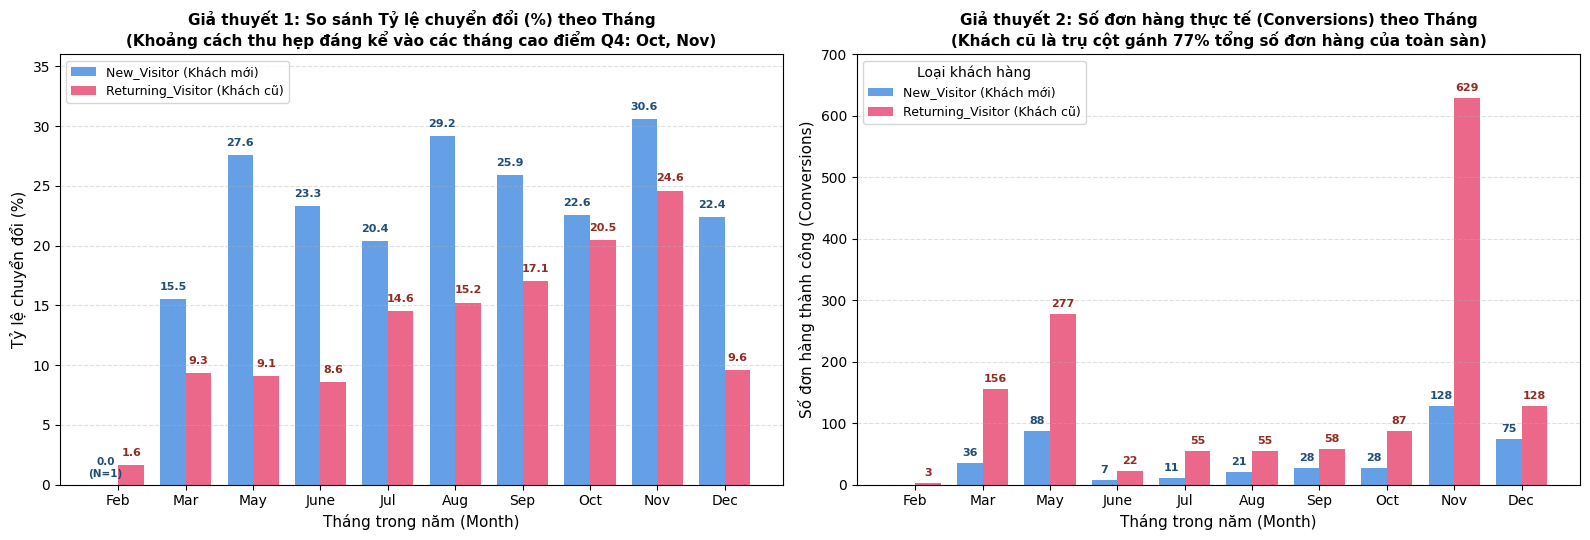

In [ ]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# 1. Tính toán bảng thống kê chi tiết Month x VisitorType
monthly_segment = (
    df.groupby(['Month', 'VisitorType'], observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
monthly_segment['conversion_rate_pct'] = (monthly_segment['conversion_rate'] * 100).round(2)
monthly_segment.drop(columns=['conversion_rate'], inplace=True)

pivot_all = monthly_segment.pivot(
    index='Month', 
    columns='VisitorType', 
    values=['sessions', 'conversions', 'conversion_rate_pct']
).reindex(month_order)

print("=== BẢNG TỔNG HỢP MONTH X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===")
display(pivot_all)

# 2. Chuẩn bị dữ liệu vẽ biểu đồ kiểm chứng 2 giả thuyết (Đều dùng Biểu đồ cột đôi - Grouped Bar)
pivot_cr = monthly_segment.pivot(index='Month', columns='VisitorType', values='conversion_rate_pct').reindex(month_order)
pivot_conv = monthly_segment.pivot(index='Month', columns='VisitorType', values='conversions').reindex(month_order).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

x = np.arange(len(month_order))
width = 0.38

color_new = '#4A90E2' # Xanh dương - Khách mới
color_ret = '#E94E77' # Hồng tím - Khách cũ

# --- Biểu đồ 1: Grouped bar chart kiểm chứng Giả thuyết 1 (Tỷ lệ chuyển đổi %) ---
rects1 = axes[0].bar(x - width/2, pivot_cr['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects2 = axes[0].bar(x + width/2, pivot_cr['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects1:
    h = rect.get_height()
    if h > 0:
        axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.6),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')
    else:
        axes[0].annotate('0.0\n(N=1)', (rect.get_x() + rect.get_width() / 2., 0.5),
                         ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#1F4E79')

for rect in rects2:
    h = rect.get_height()
    if h > 0:
        axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.6),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#922B21')

axes[0].set_title('Giả thuyết 1: So sánh Tỷ lệ chuyển đổi (%) theo Tháng\n(Khoảng cách thu hẹp đáng kể vào các tháng cao điểm Q4: Oct, Nov)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=11)
axes[0].set_xlabel('Tháng trong năm (Month)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(month_order)
axes[0].set_ylim(0, 36)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].legend(frameon=True, fontsize=9)

# --- Biểu đồ 2: Grouped bar chart (Cột đôi) kiểm chứng Giả thuyết 2 (Số đơn hàng thực tế) ---
rects3 = axes[1].bar(x - width/2, pivot_conv['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects4 = axes[1].bar(x + width/2, pivot_conv['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects3:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 8),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')

for rect in rects4:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 8),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#922B21')

axes[1].set_title('Giả thuyết 2: Số đơn hàng thực tế (Conversions) theo Tháng\n(Khách cũ là trụ cột gánh 77% tổng số đơn hàng của toàn sàn)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Số đơn hàng thành công (Conversions)', fontsize=11)
axes[1].set_xlabel('Tháng trong năm (Month)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(month_order)
axes[1].set_ylim(0, 700)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].legend(title='Loại khách hàng', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

#### 3.2.3. Phân tích kết hợp: `Month × Weekend`
Kiểm chứng 2 câu hỏi hành vi mua sắm theo thời điểm:
1. **Tỷ lệ chuyển đổi (%)**: Khách hàng mua sắm vào cuối tuần (`Weekend = True`) có luôn đạt tỷ lệ chốt đơn cao hơn ngày thường (`False`) qua các tháng trong năm hay không?
2. **Đóng góp đơn hàng thực tế**: Ngày thường hay cuối tuần mới là trụ cột tạo ra phần lớn số lượng đơn hàng (`Conversions`) của từng tháng?


=== BẢNG TỔNG HỢP MONTH X WEEKEND (SESSIONS, CONVERSIONS, CR %) ===


sessions        conversions        conversion_rate_pct       
Weekend    False  True        False  True                False  True 
Month                                                                
Feb        156.0   28.0         2.0    1.0                1.28   3.57
Mar       1426.0  481.0       127.0   65.0                8.91  13.51
May       2649.0  715.0       266.0   99.0               10.04  13.85
June       241.0   47.0        24.0    5.0                9.96  10.64
Jul        328.0  104.0        50.0   16.0               15.24  15.38
Aug        337.0   96.0        64.0   12.0               18.99  12.50
Sep        352.0   96.0        64.0   22.0               18.18  22.92
Oct        405.0  144.0        85.0   30.0               20.99  20.83
Nov       2207.0  791.0       550.0  210.0               24.92  26.55
Dec       1361.0  366.0       177.0   39.0               13.01  10.66

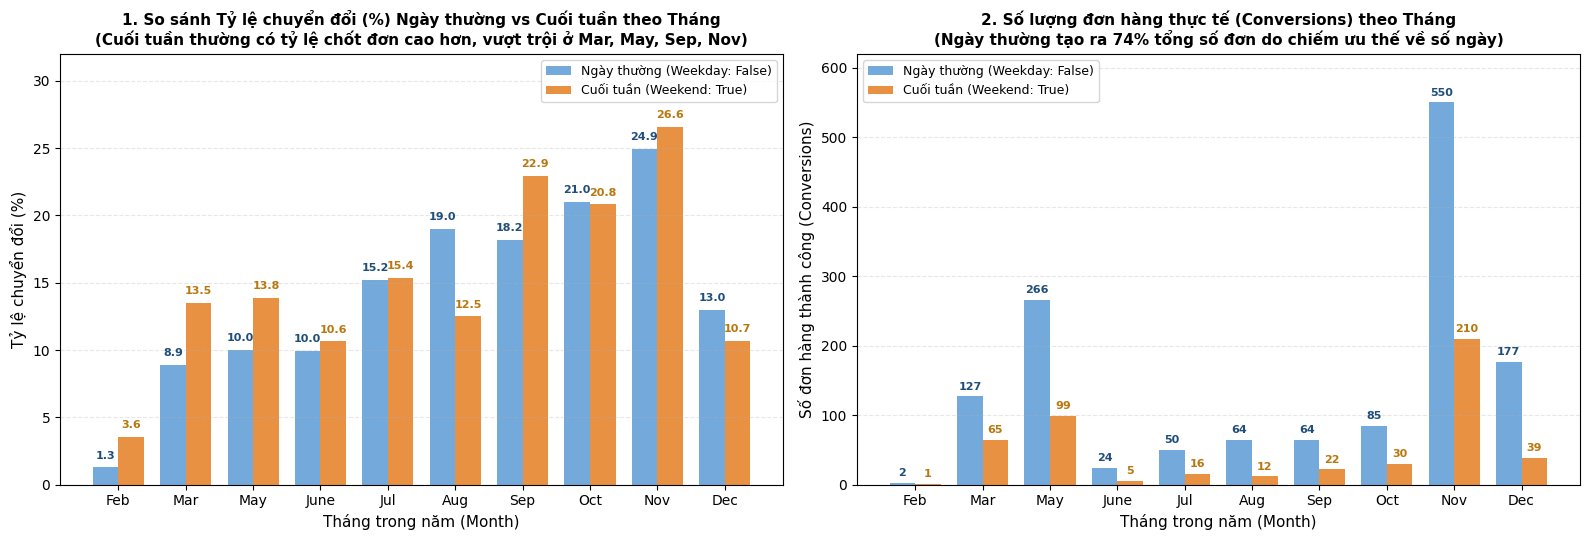

In [ ]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# 1. Tính toán bảng thống kê chi tiết Month x Weekend
mw_stat = (
    df.groupby(['Month', 'Weekend'], observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
mw_stat['conversion_rate_pct'] = (mw_stat['conversion_rate'] * 100).round(2)
mw_stat.drop(columns=['conversion_rate'], inplace=True)

pivot_all_mw = mw_stat.pivot(
    index='Month', 
    columns='Weekend', 
    values=['sessions', 'conversions', 'conversion_rate_pct']
).reindex(month_order)

print("=== BẢNG TỔNG HỢP MONTH X WEEKEND (SESSIONS, CONVERSIONS, CR %) ===")
display(pivot_all_mw)

# 2. Chuẩn bị dữ liệu vẽ biểu đồ kiểm chứng 2 câu hỏi (Đều dùng Biểu đồ cột đôi - Grouped Bar)
pivot_cr_mw = mw_stat.pivot(index='Month', columns='Weekend', values='conversion_rate_pct').reindex(month_order)
pivot_conv_mw = mw_stat.pivot(index='Month', columns='Weekend', values='conversions').reindex(month_order).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

x = np.arange(len(month_order))
width = 0.38

# --- Subplot 1: Grouped bar chart so sánh Tỷ lệ chuyển đổi (%) ---
color_weekday = '#5B9BD5'  # Xanh dương - Ngày thường
color_weekend = '#E67E22'  # Cam ấm - Cuối tuần

rects1 = axes[0].bar(x - width/2, pivot_cr_mw[False], width, label='Ngày thường (Weekday: False)', color=color_weekday, alpha=0.85)
rects2 = axes[0].bar(x + width/2, pivot_cr_mw[True], width, label='Cuối tuần (Weekend: True)', color=color_weekend, alpha=0.85)

for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.5),
                     ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')

for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.5),
                     ha='center', va='bottom', fontsize=8, fontweight='bold', color='#B9770E')

axes[0].set_title('1. So sánh Tỷ lệ chuyển đổi (%) Ngày thường vs Cuối tuần theo Tháng\n(Cuối tuần thường có tỷ lệ chốt đơn cao hơn, vượt trội ở Mar, May, Sep, Nov)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=11)
axes[0].set_xlabel('Tháng trong năm (Month)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(month_order)
axes[0].set_ylim(0, 32)
axes[0].grid(axis='y', linestyle='--', alpha=0.3)
axes[0].legend(frameon=True, fontsize=9)

# --- Subplot 2: Grouped bar chart Số đơn hàng thực tế (Conversions) ---
rects3 = axes[1].bar(x - width/2, pivot_conv_mw[False], width, label='Ngày thường (Weekday: False)', color=color_weekday, alpha=0.85)
rects4 = axes[1].bar(x + width/2, pivot_conv_mw[True], width, label='Cuối tuần (Weekend: True)', color=color_weekend, alpha=0.85)

for rect in rects3:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 7),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')

for rect in rects4:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 7),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#B9770E')

axes[1].set_title('2. Số lượng đơn hàng thực tế (Conversions) theo Tháng\n(Ngày thường tạo ra 74% tổng số đơn do chiếm ưu thế về số ngày)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Số đơn hàng thành công (Conversions)', fontsize=11)
axes[1].set_xlabel('Tháng trong năm (Month)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(month_order)
axes[1].set_ylim(0, 620)
axes[1].grid(axis='y', linestyle='--', alpha=0.3)
axes[1].legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

#### 3.2.4. Phân tích kết hợp: `TrafficType × VisitorType`
Đánh giá chất lượng và vai trò của các kênh tiếp thị lưu lượng (Traffic Sources) đối với từng nhóm khách hàng:
1. **Tỷ lệ chuyển đổi (%)**: Kênh nào là "cỗ máy săn khách mới" (Acquisition Channel) với tỷ lệ chốt đơn cao? Kênh nào giữ chân khách cũ tốt nhất?
2. **Quy mô đơn hàng thực tế (Conversions)**: Kênh nào đem lại nhiều đơn hàng nhất cho sàn? Có sự lệch pha giữa số lượng phiên truy cập và tỷ lệ chốt đơn thực tế không?

*(Ghi chú: Gom 7 loại nguồn truy cập lớn nhất chiếm ~90% lưu lượng: Type 2, 1, 3, 4, 13, 10, 8 và nhóm Other).*


=== BẢNG TỔNG HỢP TRAFFICTYPE X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===


sessions                         conversions        \
VisitorType   New_Visitor Other Returning_Visitor New_Visitor Other   
Traffic_Group                                                         
Type 2              936.0  11.0            2966.0       238.0   1.0   
Type 1               37.0   7.0            2407.0         7.0   0.0   
Type 3              140.0   7.0            1905.0        25.0   1.0   
Type 4               99.0   NaN             970.0        33.0   NaN   
Type 13               6.0   1.0             731.0         0.0   0.0   
Type 10              22.0   3.0             425.0         5.0   0.0   
Type 8              175.0   1.0             167.0        50.0   0.0   
Other               279.0  55.0             980.0        64.0  14.0   

                                conversion_rate_pct                           
VisitorType   Returning_Visitor         New_Visitor  Other Returning_Visitor  
Traffic_Group                                                                 
Type 2                    608.0               25.43   9.09             20.50  
Type 1                    255.0               18.92   0.00             10.59  
Type 3                    154.0               17.86  14.29              8.08  
Type 4                    132.0               33.33    NaN             13.61  
Type 13                    43.0                0.00   0.00              5.88  
Type 10                    85.0               22.73   0.00             20.00  
Type 8                     45.0               28.57   0.00             26.95  
Other                     148.0               22.94  25.45             15.10

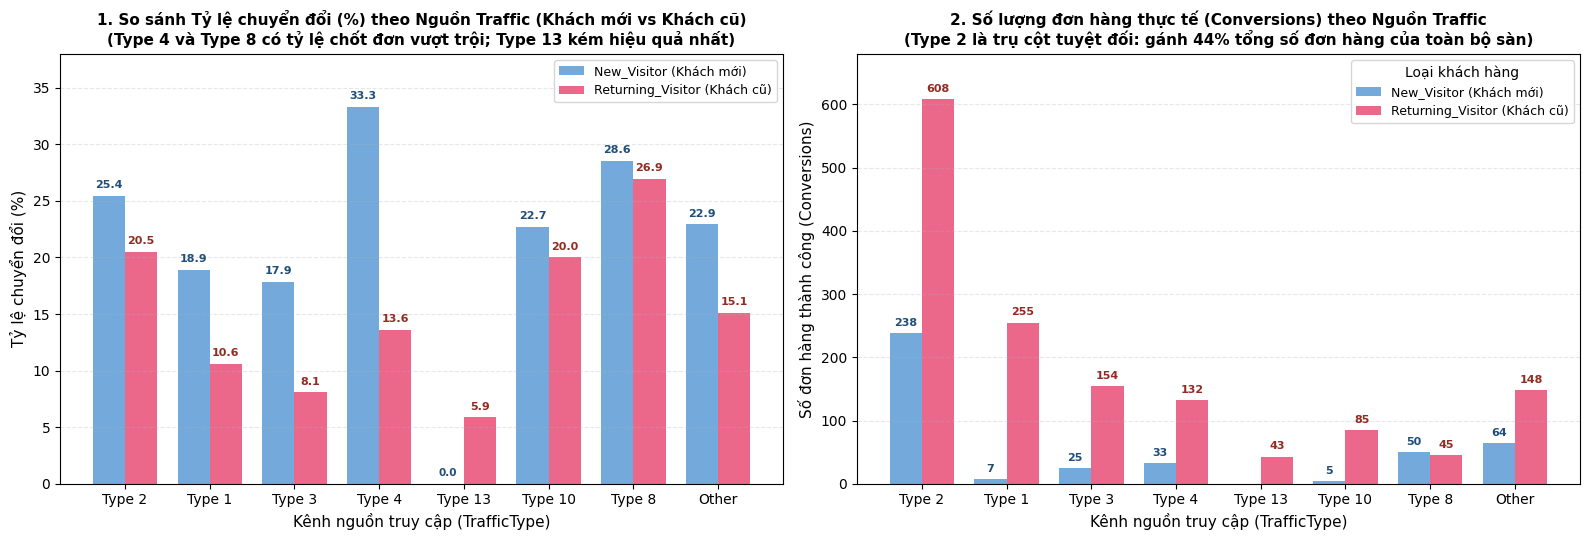

In [ ]:
# 1. Gom nhóm Top 7 TrafficType chiếm ~90% phiên + nhóm Other
top_tt = [2, 1, 3, 4, 13, 10, 8]
df['Traffic_Group'] = df['TrafficType'].apply(lambda x: f'Type {x}' if x in top_tt else 'Other')
tt_order = [f'Type {x}' for x in top_tt] + ['Other']

# 2. Tính toán bảng thống kê chi tiết TrafficGroup x VisitorType
tt_vt_stat = (
    df.groupby(['Traffic_Group', 'VisitorType'], observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
tt_vt_stat['conversion_rate_pct'] = (tt_vt_stat['conversion_rate'] * 100).round(2)
tt_vt_stat.drop(columns=['conversion_rate'], inplace=True)

pivot_all_tt = tt_vt_stat.pivot(
    index='Traffic_Group', 
    columns='VisitorType', 
    values=['sessions', 'conversions', 'conversion_rate_pct']
).reindex(tt_order)

print("=== BẢNG TỔNG HỢP TRAFFICTYPE X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===")
display(pivot_all_tt)

# 3. Chuẩn bị dữ liệu vẽ biểu đồ kiểm chứng 2 câu hỏi (Đều dùng Biểu đồ cột đôi - Grouped Bar)
pivot_cr_tt = tt_vt_stat.pivot(index='Traffic_Group', columns='VisitorType', values='conversion_rate_pct').reindex(tt_order)
pivot_conv_tt = tt_vt_stat.pivot(index='Traffic_Group', columns='VisitorType', values='conversions').reindex(tt_order).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

x = np.arange(len(tt_order))
width = 0.38

color_new = '#5B9BD5'  # Xanh dương - Khách mới
color_ret = '#E94E77'  # Hồng tím - Khách cũ

# --- Subplot 1: Grouped bar chart Tỷ lệ chuyển đổi (%) ---
rects1 = axes[0].bar(x - width/2, pivot_cr_tt['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects2 = axes[0].bar(x + width/2, pivot_cr_tt['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects1:
    h = rect.get_height()
    if h > 0:
        axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.5),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')
    else:
        axes[0].annotate('0.0', (rect.get_x() + rect.get_width() / 2., 0.5),
                         ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#1F4E79')

for rect in rects2:
    h = rect.get_height()
    if h > 0:
        axes[0].annotate(f'{h:.1f}', (rect.get_x() + rect.get_width() / 2., h + 0.5),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#922B21')

axes[0].set_title('1. So sánh Tỷ lệ chuyển đổi (%) theo Nguồn Traffic (Khách mới vs Khách cũ)\n(Type 4 và Type 8 có tỷ lệ chốt đơn vượt trội; Type 13 kém hiệu quả nhất)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=11)
axes[0].set_xlabel('Kênh nguồn truy cập (TrafficType)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tt_order)
axes[0].set_ylim(0, 38)
axes[0].grid(axis='y', linestyle='--', alpha=0.3)
axes[0].legend(frameon=True, fontsize=9)

# --- Subplot 2: Grouped bar chart Số đơn hàng thực tế (Conversions) ---
rects3 = axes[1].bar(x - width/2, pivot_conv_tt['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects4 = axes[1].bar(x + width/2, pivot_conv_tt['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects3:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 8),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F4E79')

for rect in rects4:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 8),
                         ha='center', va='bottom', fontsize=8, fontweight='bold', color='#922B21')

axes[1].set_title('2. Số lượng đơn hàng thực tế (Conversions) theo Nguồn Traffic\n(Type 2 là trụ cột tuyệt đối: gánh 44% tổng số đơn hàng của toàn bộ sàn)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Số đơn hàng thành công (Conversions)', fontsize=11)
axes[1].set_xlabel('Kênh nguồn truy cập (TrafficType)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(tt_order)
axes[1].set_ylim(0, 680)
axes[1].grid(axis='y', linestyle='--', alpha=0.3)
axes[1].legend(title='Loại khách hàng', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


#### 3.2.5. Phân tích kết hợp: `PageValues × VisitorType`
Khảo sát mối tương tác giữa **Ý định mua sắm (thông qua bậc giá trị trang `PageValues`)** và **Loại khách hàng (`VisitorType`)**:
1. **Tỷ lệ chuyển đổi (%)**: Khi khách hàng đã tiếp cận được những trang "hái ra tiền" (`PageValues > 0`), thì Khách mới (`New_Visitor`) hay Khách cũ (`Returning_Visitor`) có quyết tâm chốt đơn cao hơn?
2. **Đóng góp đơn hàng thực tế**: Dù khách mới chuyển đổi cực cao ở nhóm trang giá trị, khách cũ đóng góp bao nhiêu đơn hàng tuyệt đối tại từng bậc điểm?


=== BẢNG TỔNG HỢP PAGEVALUES TIERS X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===


sessions                         conversions        \
VisitorType     New_Visitor Other Returning_Visitor New_Visitor Other   
PageValues_Tier                                                         
Zero (PV = 0)        1313.0  69.0            8218.0        93.0   2.0   
Low                    24.0   1.0             885.0        12.0   1.0   
Medium                112.0   1.0             797.0        97.0   1.0   
High                  245.0  14.0             651.0       220.0  12.0   

                                  conversion_rate_pct          \
VisitorType     Returning_Visitor         New_Visitor   Other   
PageValues_Tier                                                 
Zero (PV = 0)               275.0                7.08    2.90   
Low                         334.0               50.00  100.00   
Medium                      403.0               86.61  100.00   
High                        458.0               89.80   85.71   

                                   
VisitorType     Returning_Visitor  
PageValues_Tier                    
Zero (PV = 0)                3.35  
Low                         37.74  
Medium                      50.56  
High                        70.35

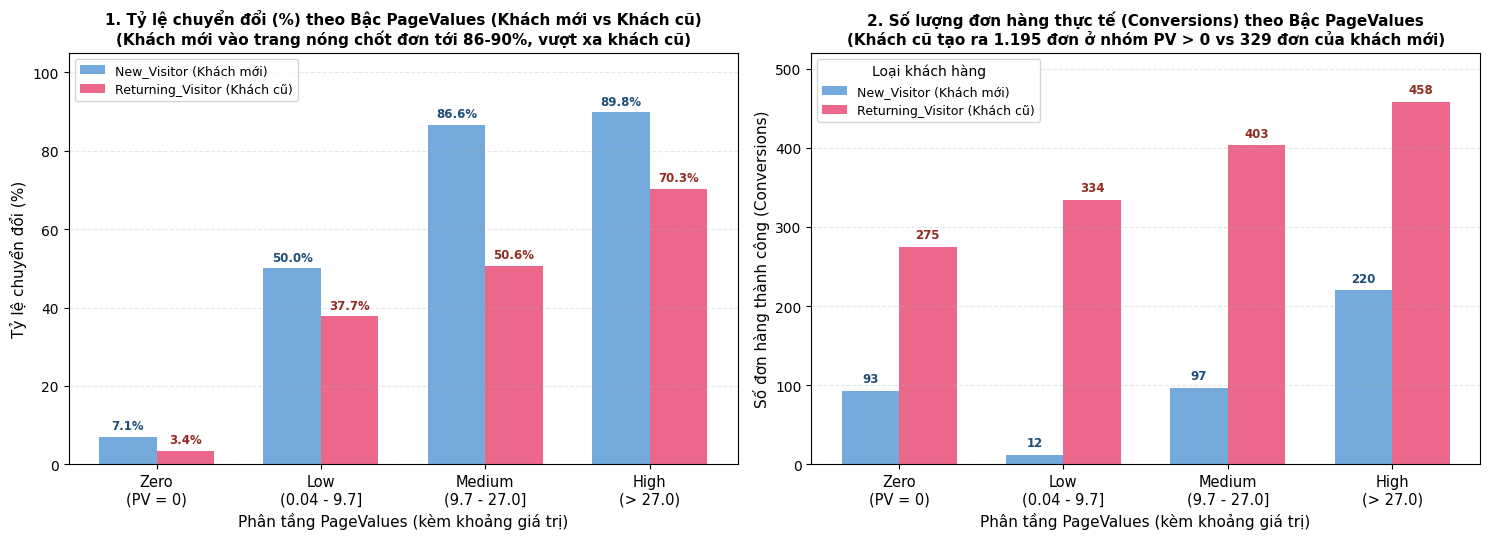

In [ ]:
# Đảm bảo phân tầng PageValues_Tier theo qcut đã có từ 3.1.3
pos_mask = df['PageValues'] > 0
pos_df = df[pos_mask].copy()
pos_df['PageValues_Tier'] = pd.qcut(pos_df['PageValues'], q=3, labels=['Low', 'Medium', 'High'])
df['PageValues_Tier'] = 'Zero (PV = 0)'
df.loc[pos_mask, 'PageValues_Tier'] = pos_df['PageValues_Tier'].astype(str)
tier_order = ['Zero (PV = 0)', 'Low', 'Medium', 'High']
df['PageValues_Tier'] = pd.Categorical(df['PageValues_Tier'], categories=tier_order, ordered=True)

# 1. Tính toán bảng thống kê chi tiết PageValues_Tier x VisitorType
pv_vt_stat = (
    df.groupby(['PageValues_Tier', 'VisitorType'], observed=True)['Revenue']
      .agg(sessions='size', conversions='sum', conversion_rate='mean')
      .reset_index()
)
pv_vt_stat['conversion_rate_pct'] = (pv_vt_stat['conversion_rate'] * 100).round(2)
pv_vt_stat.drop(columns=['conversion_rate'], inplace=True)

pivot_all_pv = pv_vt_stat.pivot(
    index='PageValues_Tier', 
    columns='VisitorType', 
    values=['sessions', 'conversions', 'conversion_rate_pct']
).reindex(tier_order)

print("=== BẢNG TỔNG HỢP PAGEVALUES TIERS X VISITOR TYPE (SESSIONS, CONVERSIONS, CR %) ===")
display(pivot_all_pv)

# 2. Chuẩn bị dữ liệu vẽ biểu đồ kiểm chứng 2 câu hỏi (Đều dùng Biểu đồ cột đôi - Grouped Bar)
pivot_cr_pv = pv_vt_stat.pivot(index='PageValues_Tier', columns='VisitorType', values='conversion_rate_pct').reindex(tier_order)
pivot_conv_pv = pv_vt_stat.pivot(index='PageValues_Tier', columns='VisitorType', values='conversions').reindex(tier_order).fillna(0)

# Nhãn trục X dạng 2 dòng: dòng trên tên bậc, dòng dưới khoảng giá trị cụ thể
detailed_labels = [
    'Zero\n(PV = 0)',
    'Low\n(0.04 - 9.7]',
    'Medium\n(9.7 - 27.0]',
    'High\n(> 27.0)'
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

x = np.arange(len(tier_order))
width = 0.35

color_new = '#5B9BD5' # Xanh dương - Khách mới
color_ret = '#E94E77' # Hồng tím - Khách cũ

# --- Subplot 1: Grouped bar chart Tỷ lệ chuyển đổi (%) ---
rects1 = axes[0].bar(x - width/2, pivot_cr_pv['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects2 = axes[0].bar(x + width/2, pivot_cr_pv['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width() / 2., h + 1.2),
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1F4E79')

for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width() / 2., h + 1.2),
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#922B21')

axes[0].set_title('1. Tỷ lệ chuyển đổi (%) theo Bậc PageValues (Khách mới vs Khách cũ)\n(Khách mới vào trang nóng chốt đơn tới 86-90%, vượt xa khách cũ)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Tỷ lệ chuyển đổi (%)', fontsize=11)
axes[0].set_xlabel('Phân tầng PageValues (kèm khoảng giá trị)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(detailed_labels, fontsize=10.5)
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', linestyle='--', alpha=0.3)
axes[0].legend(frameon=True, fontsize=9)

# --- Subplot 2: Grouped bar chart Số đơn hàng thực tế (Conversions) ---
rects3 = axes[1].bar(x - width/2, pivot_conv_pv['New_Visitor'], width, label='New_Visitor (Khách mới)', color=color_new, alpha=0.85)
rects4 = axes[1].bar(x + width/2, pivot_conv_pv['Returning_Visitor'], width, label='Returning_Visitor (Khách cũ)', color=color_ret, alpha=0.85)

for rect in rects3:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 7),
                         ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1F4E79')

for rect in rects4:
    h = rect.get_height()
    if h > 0:
        axes[1].annotate(f'{int(h)}', (rect.get_x() + rect.get_width() / 2., h + 7),
                         ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#922B21')

axes[1].set_title('2. Số lượng đơn hàng thực tế (Conversions) theo Bậc PageValues\n(Khách cũ tạo ra 1.195 đơn ở nhóm PV > 0 vs 329 đơn của khách mới)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Số đơn hàng thành công (Conversions)', fontsize=11)
axes[1].set_xlabel('Phân tầng PageValues (kèm khoảng giá trị)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(detailed_labels, fontsize=10.5)
axes[1].set_ylim(0, 520)
axes[1].grid(axis='y', linestyle='--', alpha=0.3)
axes[1].legend(title='Loại khách hàng', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


### 3.3. Phân tích tương quan đa biến & Thử nghiệm Feature Engineering
#### 3.3.1. Ma trận tương quan Spearman (Spearman Correlation Matrix)
Sử dụng tương quan hạng Spearman (thay vì Pearson) để đo lường mối quan hệ đơn điệu giữa các biến có phân phối lệch và kiểm tra hiện tượng đa cộng tuyến (Multicollinearity).


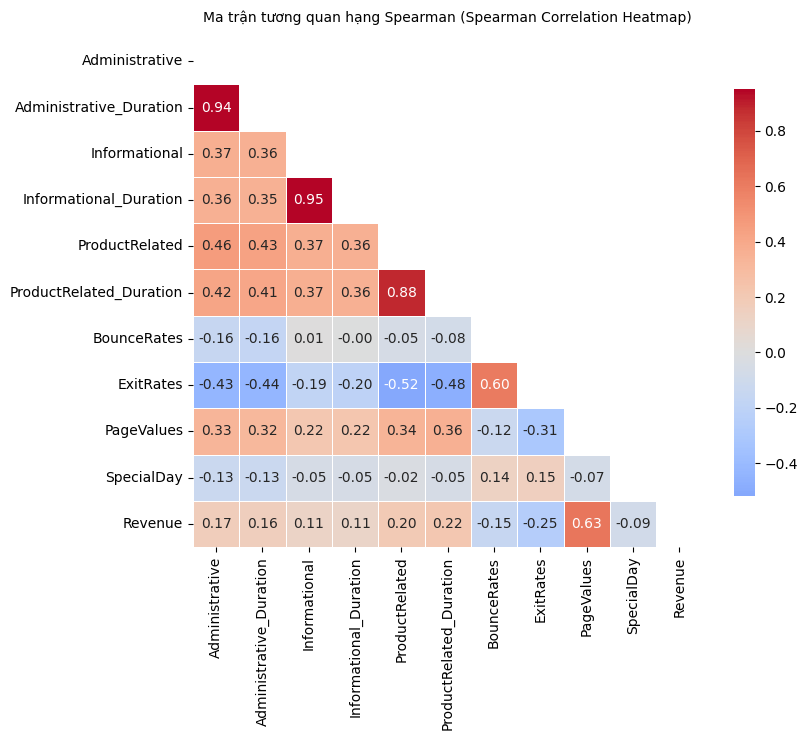

In [ ]:
numeric_for_corr = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue'
]

corr = df[numeric_for_corr].corr(method='spearman')

plt.figure(figsize=(8.5, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5, 
    cbar_kws={'shrink': 0.8}
)
plt.title('Ma trận tương quan hạng Spearman (Spearman Correlation Heatmap)', fontsize=10, pad=12)
plt.tight_layout()
plt.show()

In [ ]:
corr.round(2)[:].to_csv('corr.csv')

### 3.4. Tổng kết Giai đoạn 3

| Câu hỏi | Phát hiện chính | Hệ quả cho Modeling |
|---|---|---|
| **Hành vi nào gắn với mua hàng?** | • **`PageValues` là đặc trưng phân loại tốt**: PV > 0 có tỷ lệ mua 56.3% vs 3.9% khi PV = 0. Khi chia 3 bậc (Low/Med/High), tỷ lệ chốt đơn tăng lũy tiến từ 38.1% → 55.1% → 75.8%.<br>• **Trang xem & Thời lượng**: Người mua xem số trang sản phẩm gấp ~1.8 lần (median 29 vs 16) và ở lại lâu hơn ~2.2 lần (1,110s vs 510s).<br>• **Tỷ lệ thoát**: `ExitRates` ở người mua thấp hơn rõ rệt (median 0.016 vs 0.029). | • `PageValues` là đặc trưng số 1 (cần kiểm tra baseline khi có và không có biến này). Tạo cờ nhị phân `has_page_values` và bậc `PageValues_Tier`.<br>• Tạo đặc trưng tương tác: `PageValues × VisitorType`. |
| **Nhóm khách & bối cảnh nào mua nhiều?** | • **Loại khách**: Khách mới có tỷ lệ mua cao hơn (24.9% vs 13.9%), nhưng khách cũ chiếm đa số lượng đơn (77%).<br>• **Mùa vụ (`Month × Weekend`)**: Tháng 11 đạt đỉnh cả về lượng phiên (2,998) lẫn số đơn (760 đơn - chiếm 40% cả năm). Cuối tuần tăng nhẹ tỷ lệ mua ở hầu hết các tháng (17.4% vs 14.9%), riêng Tháng 11 tỷ lệ mua đều cao (~25-26%) ở cả ngày thường và cuối tuần.<br>• **Kênh truy cập (`TrafficType × VisitorType`)**: Phân hóa mạnh theo nguồn (Kênh 2 đạt 21.6%, Kênh 13 chỉ đạt 5.8%). Khách mới từ Kênh 2 có tỷ lệ mua vượt trội (32.8%).<br>• **Ngày lễ (`SpecialDay`)**: 90% phiên bằng 0; cận ngày lễ tỷ lệ mua giảm mạnh (3.4% – 8.3% so với 16.5% ngày thường). | • Giữ các biến phân loại: `Month`, `VisitorType`, `Weekend`, `TrafficType`.<br>• `SpecialDay` thưa thớt, nên mã hóa dạng cờ nhị phân `has_special_day` thay vì giá trị liên tục.<br>• Thử nghiệm đặc trưng tương tác: `Month × VisitorType`, `Month × Weekend`, `TrafficType × VisitorType`. |
| **Tương quan & đa cộng tuyến?** | • **Tương quan với `Revenue`**: Chỉ `PageValues` tương quan mạnh (+0.63), `ExitRates` âm vừa (-0.25), `ProductRelated_Duration` (+0.22); các biến còn lại tương quan yếu (\|r\| ≤ 0.20).<br>• **Đa cộng tuyến giữa các cặp biến**: Số trang và thời lượng của cùng 1 nhóm trang gần như trùng nhau (r từ 0.88 đến 0.95); `ExitRates` và `BounceRates` tương quan khá cao (0.60). | • Với mô hình tuyến tính / Mạng nơ-ron: Cần bỏ bớt 1 biến ở mỗi cặp trùng lặp hoặc dùng L1/L2 Regularization.<br>• Với mô hình cây (XGBoost, LightGBM): Giữ nguyên vì cây quyết định xử lý tốt tương quan và phi tuyến tính. |
